# Layers 6–8: 3CosAdd vs. 3CosMul, raw wav2vec2 and word probe

**Question:** does the analogy scoring rule change the past-tense results, and does the answer depend on the layer or on the representation?

- **3CosAdd** (Mikolov et al. 2013), the paper's rule: rank every word token by its cosine to *b + a\* − a*.
- **3CosMul** (Levy & Goldberg 2014): rank by cos(x, a\*) · cos(x, b) / (cos(x, a) + ε), each cosine shifted to [0, 1].

Two representations, both from wav2vec2-base:
- **Wav2Vec**: the raw hidden states of the layer (768 numbers per frame), averaged over each word.
- **Word**: the trained word probe (`ffff_32`) on top of that layer (32 numbers per frame), averaged over each word.

So there are 3 layers × 2 representations × 2 rules = **12 results files**. The notebook measures both **accuracy** (top-1: is the correct word the nearest?) and **ranking** (where the correct word lands: mean rank, median rank, and the share of trials with the correct word in the top 5 / 10 / 100).

**Same trials.** All runs draw their analogies with the same seed, so trial *i* of an experiment is the same *a : a\* :: b : ?* question in all 12 files. Section 6 uses that for a trial-by-trial comparison.

**What you need**
- 3CosAdd (Alliance runs, all experiments): `outputs/analogy/runs/…` (Word) and `outputs/analogy/runs_id/…` (Wav2Vec).
- 3CosMul (Mac runs, `scripts/mac/run_layers_3cosmul.py`): `outputs/analogy/runs_3cosmul/…` and `outputs/analogy/runs_id_3cosmul/…`. They hold only the four experiments used here: `basic`, `regular`, `random_to_NNS`, `random_to_VBZ`.
- Python with `pandas`, `numpy`, `matplotlib`, `seaborn` (the `m2v-layers` env). No GPU or PyTorch.

**What it produces:** tables and figures in `outputs/feasibility/layers678_3cosadd_vs_3cosmul/`.

## 1. Setup

Imports the per-layer analysis (`scripts/layers/compare_layers.py`, as `L`) and the feasibility helpers (`C`).

- `LAYERS`: the layers to compare.
- `N_BOOT`: bootstrap resamples for the confidence intervals. 2000 matches the other notebooks (the full run takes a few minutes); use e.g. 300 for a quick look.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

# find the repo root (the folder that contains scripts/layers/)
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/layers/compare_layers.py").exists())
sys.path.insert(0, str(REPO / "scripts/layers"))
import compare_layers as L      # per-layer analysis (this project)
C = L.C                         # feasibility common.py: paths, constants, rank_summary(), plotting helpers

LAYERS = [6, 7, 8]
N_BOOT = 2000
MODELS = ["Wav2Vec", "Word"]
MODEL_NAMES = {"Wav2Vec": "raw wav2vec2", "Word": "word probe"}
METHODS = {"3CosAdd": "3cosadd", "3CosMul": "3cosmul"}   # label -> analogy_method in the file paths
# Okabe-Ito blue / vermillion; checked for colour-blind separation (dataviz validate_palette.js)
COLORS = {"3CosAdd": "#0072B2", "3CosMul": "#D55E00"}
MARKERS = {"3CosAdd": "o", "3CosMul": "s"}

C.MODELS[:] = MODELS
OUT = C.FEAS / "layers678_3cosadd_vs_3cosmul"
TABLES, FIGURES = OUT / "tables", OUT / "figures"
TABLES.mkdir(parents=True, exist_ok=True); FIGURES.mkdir(parents=True, exist_ok=True)

def results_path(method, layer, model):
    L.ANALOGY_METHOD = method
    return L.results_paths(layer)[model]

def savefig(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=200, bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(FIGURES / f"{name}.png")))

C.set_style()
pd.set_option("display.width", 180, "display.max_columns", 40)
print("repo:", REPO)

repo: /Users/tanyadjavaherpour/Documents/McMaster/RA/Morph-2-Vec


## 2. Check the results files

All 12 files must exist. For the 3CosMul runs, `EXPERIMENTS.txt` says which experiments were scored.

In [2]:
files = []
for layer in LAYERS:
    for model in MODELS:
        for label, method in METHODS.items():
            p = results_path(method, layer, model)
            exp = p.parent / "EXPERIMENTS.txt"
            files.append({"layer": layer, "model": model, "method": label, "exists": p.exists(),
                          "experiments": exp.read_text().strip().replace("\n", ", ") if exp.exists() else "all",
                          "path": str(p.relative_to(REPO))})
files = pd.DataFrame(files)
display(files)
assert files.exists.all(), "missing results files:\n" + "\n".join(files.path[~files.exists])

,layer,model,method,exists,experiments,path
0,6,Wav2Vec,3CosAdd,True,all,outputs/analogy/runs_id/librispeech-train-clea...
1,6,Wav2Vec,3CosMul,True,"subset (Mac run):, basic, regular, random_to_N...",outputs/analogy/runs_id_3cosmul/librispeech-tr...
2,6,Word,3CosAdd,True,all,outputs/analogy/runs/librispeech-train-clean-1...
3,6,Word,3CosMul,True,"subset (Mac run):, basic, regular, random_to_N...",outputs/analogy/runs_3cosmul/librispeech-train...
4,7,Wav2Vec,3CosAdd,True,all,outputs/analogy/runs_id/librispeech-train-clea...
5,7,Wav2Vec,3CosMul,True,"subset (Mac run):, basic, regular, random_to_N...",outputs/analogy/runs_id_3cosmul/librispeech-tr...
6,7,Word,3CosAdd,True,all,outputs/analogy/runs/librispeech-train-clean-1...
7,7,Word,3CosMul,True,"subset (Mac run):, basic, regular, random_to_N...",outputs/analogy/runs_3cosmul/librispeech-train...
8,8,Wav2Vec,3CosAdd,True,all,outputs/analogy/runs_id/librispeech-train-clea...
9,8,Wav2Vec,3CosMul,True,"subset (Mac run):, basic, regular, random_to_N...",outputs/analogy/runs_id_3cosmul/librispeech-tr...


## 3. Pair the trials and check every run is sane

For each layer and representation, this lines up trial *i* of each experiment in the 3CosAdd and the 3CosMul file. The words must be identical in every pair; otherwise the runs did not use the same trials.

It also checks that every run does **much better than chance** on `basic` (median rank below 100). A run that scored misaligned vectors (e.g. the first Mac run, extracted in the wrong utterance order; see `scripts/mac/recover_cluster_order.py`) has median ranks in the thousands, and the notebook stops.

In [3]:
CHECK_SANITY = True   # set False only to test the notebook's code on a run you know is broken

keys = ["experiment", "trial_idx"]
words = ["base_from", "inflected_from", "base_to", "inflected_to"]
raw, paired = {}, []
for layer in LAYERS:
    for model in MODELS:
        for label, method in METHODS.items():
            C.RESULTS = {model: results_path(method, layer, model)}
            raw[layer, model, label] = L.E.export_results(model)
        mul, add = raw[layer, model, "3CosMul"], raw[layer, model, "3CosAdd"]
        add = add[add.experiment.isin(set(mul.experiment))]
        p = add[keys + words + ["group0", "group1", "gt_label_rank"]].merge(
            mul[keys + words + ["gt_label_rank"]], on=keys, suffixes=("_add", "_mul"), how="inner")
        same = np.all([p[f"{w}_add"] == p[f"{w}_mul"] for w in words], axis=0)
        print(f"layer {layer} {model:7s}: {len(p):,} paired trials, same words in {same.mean():.1%}")
        assert same.all() and len(p) == len(mul) == len(add), f"layer {layer} {model}: the two runs did not score the same trials"
        p = p.rename(columns={f"{w}_add": w for w in words}).drop(columns=[f"{w}_mul" for w in words])
        paired.append(p.assign(layer=layer, model=model))
paired = pd.concat(paired, ignore_index=True)

sanity = pd.DataFrame([{"layer": layer, "model": model, "method": label,
                        "basic median rank": r.query("experiment == 'basic'").gt_label_rank.median(),
                        "basic top-1": (r.query("experiment == 'basic'").gt_label_rank == 0).mean()}
                       for (layer, model, label), r in raw.items()])
display(sanity.pivot_table(index=["model", "layer"], columns="method", values=["basic top-1", "basic median rank"]).round(3))
if CHECK_SANITY:
    bad = sanity[sanity["basic median rank"] >= 100]
    assert bad.empty, f"chance-level runs (misaligned vectors?):\n{bad}"

layer 6 Wav2Vec: 14,868 paired trials, same words in 100.0%
layer 6 Word   : 14,868 paired trials, same words in 100.0%
layer 7 Wav2Vec: 14,868 paired trials, same words in 100.0%
layer 7 Word   : 14,868 paired trials, same words in 100.0%
layer 8 Wav2Vec: 14,868 paired trials, same words in 100.0%
layer 8 Word   : 14,868 paired trials, same words in 100.0%


basic median rank         basic top-1        
method                  3CosAdd 3CosMul     3CosAdd 3CosMul
model   layer                                              
Wav2Vec 6                   0.0     0.0       0.555   0.561
        7                   0.0     0.0       0.599   0.619
        8                   0.0     0.0       0.594   0.602
Word    6                   0.0     4.0       0.666   0.342
        7                   0.0     3.0       0.710   0.356
        8                   0.0     2.0       0.692   0.388

## 4. Accuracy and mean rank by condition

The conditions of Figure 7 in the feasibility notebook (all *within-class* analogies):
- **past, regular**: regular [t]/[d]/[ɪd] pasts (automatic class), e.g. *walk : walked :: play : ?*
- **past, irregular**: irregular pasts without modals, *be* and homographs.
- **plural -s**, **3sg -s**: the paper's inflections.
- **random pair**: the control, an analogy whose difference vector is meaningless (lower is better here: it should *not* work).

Measures: **top-1 accuracy** (higher is better) and **mean rank** (lower is better; driven by a few very bad trials, so on a log scale). The 95% confidence intervals resample *verbs*, not trials.

In [4]:
pairs = L.load_pairs()
grid, cond, per_verb = [], [], []
for label, method in METHODS.items():
    for layer in LAYERS:
        print(label, "layer", layer, "...", flush=True)
        L.ANALOGY_METHOD = method
        g, c, v = L.layer_tables(layer, pairs, N_BOOT)
        grid.append(g.assign(method=label)); cond.append(c.assign(method=label)); per_verb.append(v.assign(method=label))
grid, cond, per_verb = (pd.concat(x, ignore_index=True) for x in (grid, cond, per_verb))

SHOW = [L.COND_PAST_REG_CLEAN, L.COND_PAST_IRR_CLEAN, L.COND_NNS, L.COND_VBZ, L.COND_RANDOM]
NAMES = {k: v[3] for k, v in L.COND_STYLE.items()}
c = cond[cond.condition.isin(SHOW)].copy()
c["condition"] = pd.Categorical(c.condition.map(NAMES), [NAMES[k] for k in SHOW])
c["top-1 [95% CI]"] = c.apply(lambda r: f"{r.top1:.2f} [{r.top1_lo:.2f}, {r.top1_hi:.2f}]", axis=1)
c["mean rank [95% CI]"] = c.apply(lambda r: f"{r.mean_rank:.0f} [{r.mean_lo:.0f}, {r.mean_hi:.0f}]", axis=1)
for col in ["top-1 [95% CI]", "mean rank [95% CI]", "median_rank"]:
    display(Markdown(f"**{col}**"))
    display(c.pivot_table(index=["model", "condition"], columns=["layer", "method"], values=col, aggfunc="first", observed=True))

3CosAdd layer 6 ...
3CosAdd layer 7 ...
3CosAdd layer 8 ...
3CosMul layer 6 ...
3CosMul layer 7 ...
3CosMul layer 8 ...


**top-1 [95% CI]**

layer                                    6                                     7                                     8                   
method                             3CosAdd            3CosMul            3CosAdd            3CosMul            3CosAdd            3CosMul
model   condition                                                                                                                        
Wav2Vec past, regular    0.65 [0.61, 0.69]  0.63 [0.60, 0.67]  0.73 [0.69, 0.76]  0.73 [0.70, 0.77]  0.71 [0.68, 0.74]  0.70 [0.67, 0.74]
        past, irregular  0.13 [0.09, 0.17]  0.13 [0.10, 0.17]  0.21 [0.16, 0.27]  0.23 [0.18, 0.29]  0.19 [0.14, 0.24]  0.21 [0.16, 0.26]
        plural -s        0.75 [0.72, 0.78]  0.75 [0.72, 0.78]  0.80 [0.77, 0.83]  0.83 [0.81, 0.86]  0.81 [0.79, 0.84]  0.83 [0.80, 0.85]
        3sg -s           0.75 [0.72, 0.78]  0.76 [0.72, 0.79]  0.78 [0.75, 0.81]  0.80 [0.77, 0.83]  0.77 [0.74, 0.81]  0.79 [0.75, 0.82]
        random pair      0.10 [0.08, 0.11]  0.07 [0.06, 0.08]  0.12 [0.11, 0.14]  0.10 [0.08, 0.11]  0.13 [0.11, 0.14]  0.09 [0.08, 0.10]
Word    past, regular    0.75 [0.72, 0.78]  0.47 [0.43, 0.50]  0.79 [0.76, 0.82]  0.45 [0.41, 0.48]  0.78 [0.75, 0.81]  0.43 [0.40, 0.47]
        past, irregular  0.16 [0.13, 0.19]  0.06 [0.04, 0.07]  0.21 [0.17, 0.25]  0.09 [0.07, 0.12]  0.24 [0.20, 0.28]  0.09 [0.07, 0.12]
        plural -s        0.85 [0.83, 0.88]  0.29 [0.26, 0.32]  0.93 [0.91, 0.95]  0.35 [0.32, 0.38]  0.89 [0.87, 0.91]  0.50 [0.47, 0.54]
        3sg -s           0.85 [0.82, 0.87]  0.28 [0.25, 0.31]  0.89 [0.87, 0.92]  0.32 [0.29, 0.35]  0.89 [0.86, 0.91]  0.40 [0.37, 0.43]
        random pair      0.01 [0.01, 0.02]  0.00 [0.00, 0.00]  0.02 [0.01, 0.03]  0.00 [0.00, 0.00]  0.02 [0.01, 0.03]  0.00 [0.00, 0.00]

**mean rank [95% CI]**

layer                                       6                                           7                                           8                      
method                                3CosAdd               3CosMul               3CosAdd               3CosMul               3CosAdd               3CosMul
model   condition                                                                                                                                          
Wav2Vec past, regular              18 [4, 45]            24 [6, 59]              4 [2, 9]             7 [2, 18]              5 [2, 8]             6 [3, 13]
        past, irregular     1873 [1173, 2589]     2040 [1313, 2763]      1267 [742, 1870]      1424 [871, 2025]     1721 [1028, 2413]     1828 [1110, 2544]
        plural -s                  11 [1, 31]            18 [1, 50]              3 [1, 7]             5 [1, 13]              2 [1, 3]              3 [1, 8]
        3sg -s                      6 [2, 12]             5 [2, 10]              4 [1, 8]              3 [1, 6]             5 [1, 11]              4 [1, 8]
        random pair          1024 [838, 1228]     1557 [1322, 1802]        667 [530, 832]      1062 [868, 1280]       911 [745, 1106]     1424 [1195, 1672]
Word    past, regular                3 [2, 4]           24 [18, 32]              2 [1, 3]           23 [18, 29]              4 [3, 7]           43 [32, 54]
        past, irregular     2139 [1448, 2931]     4232 [3152, 5376]      1519 [916, 2191]     2832 [1978, 3731]      1338 [831, 1926]     2813 [2037, 3729]
        plural -s                    1 [0, 1]           33 [26, 40]              0 [0, 1]           19 [15, 23]              0 [0, 1]           18 [14, 22]
        3sg -s                       3 [1, 5]           57 [36, 86]              1 [0, 1]           27 [21, 35]              2 [1, 3]           45 [25, 74]
        random pair      13184 [12021, 14538]  23030 [21484, 24765]  14699 [13374, 16189]  24797 [23069, 26673]  11671 [10579, 12930]  23093 [21483, 24784]

**median_rank**

layer                         6               7               8        
method                  3CosAdd 3CosMul 3CosAdd 3CosMul 3CosAdd 3CosMul
model   condition                                                      
Wav2Vec past, regular       0.0     0.0     0.0     0.0     0.0     0.0
        past, irregular    48.0    47.5    21.0    18.0    23.0    19.0
        plural -s           0.0     0.0     0.0     0.0     0.0     0.0
        3sg -s              0.0     0.0     0.0     0.0     0.0     0.0
        random pair        46.0   108.0    27.0    50.0    31.0    70.0
Word    past, regular       0.0     1.0     0.0     1.0     0.0     1.0
        past, irregular    76.5   344.0    28.0   184.5    33.0   181.5
        plural -s           0.0     3.0     0.0     2.0     0.0     0.0
        3sg -s              0.0     4.0     0.0     3.0     0.0     1.0
        random pair      2544.0  8694.5  2846.5  8560.5  2219.5  8794.0

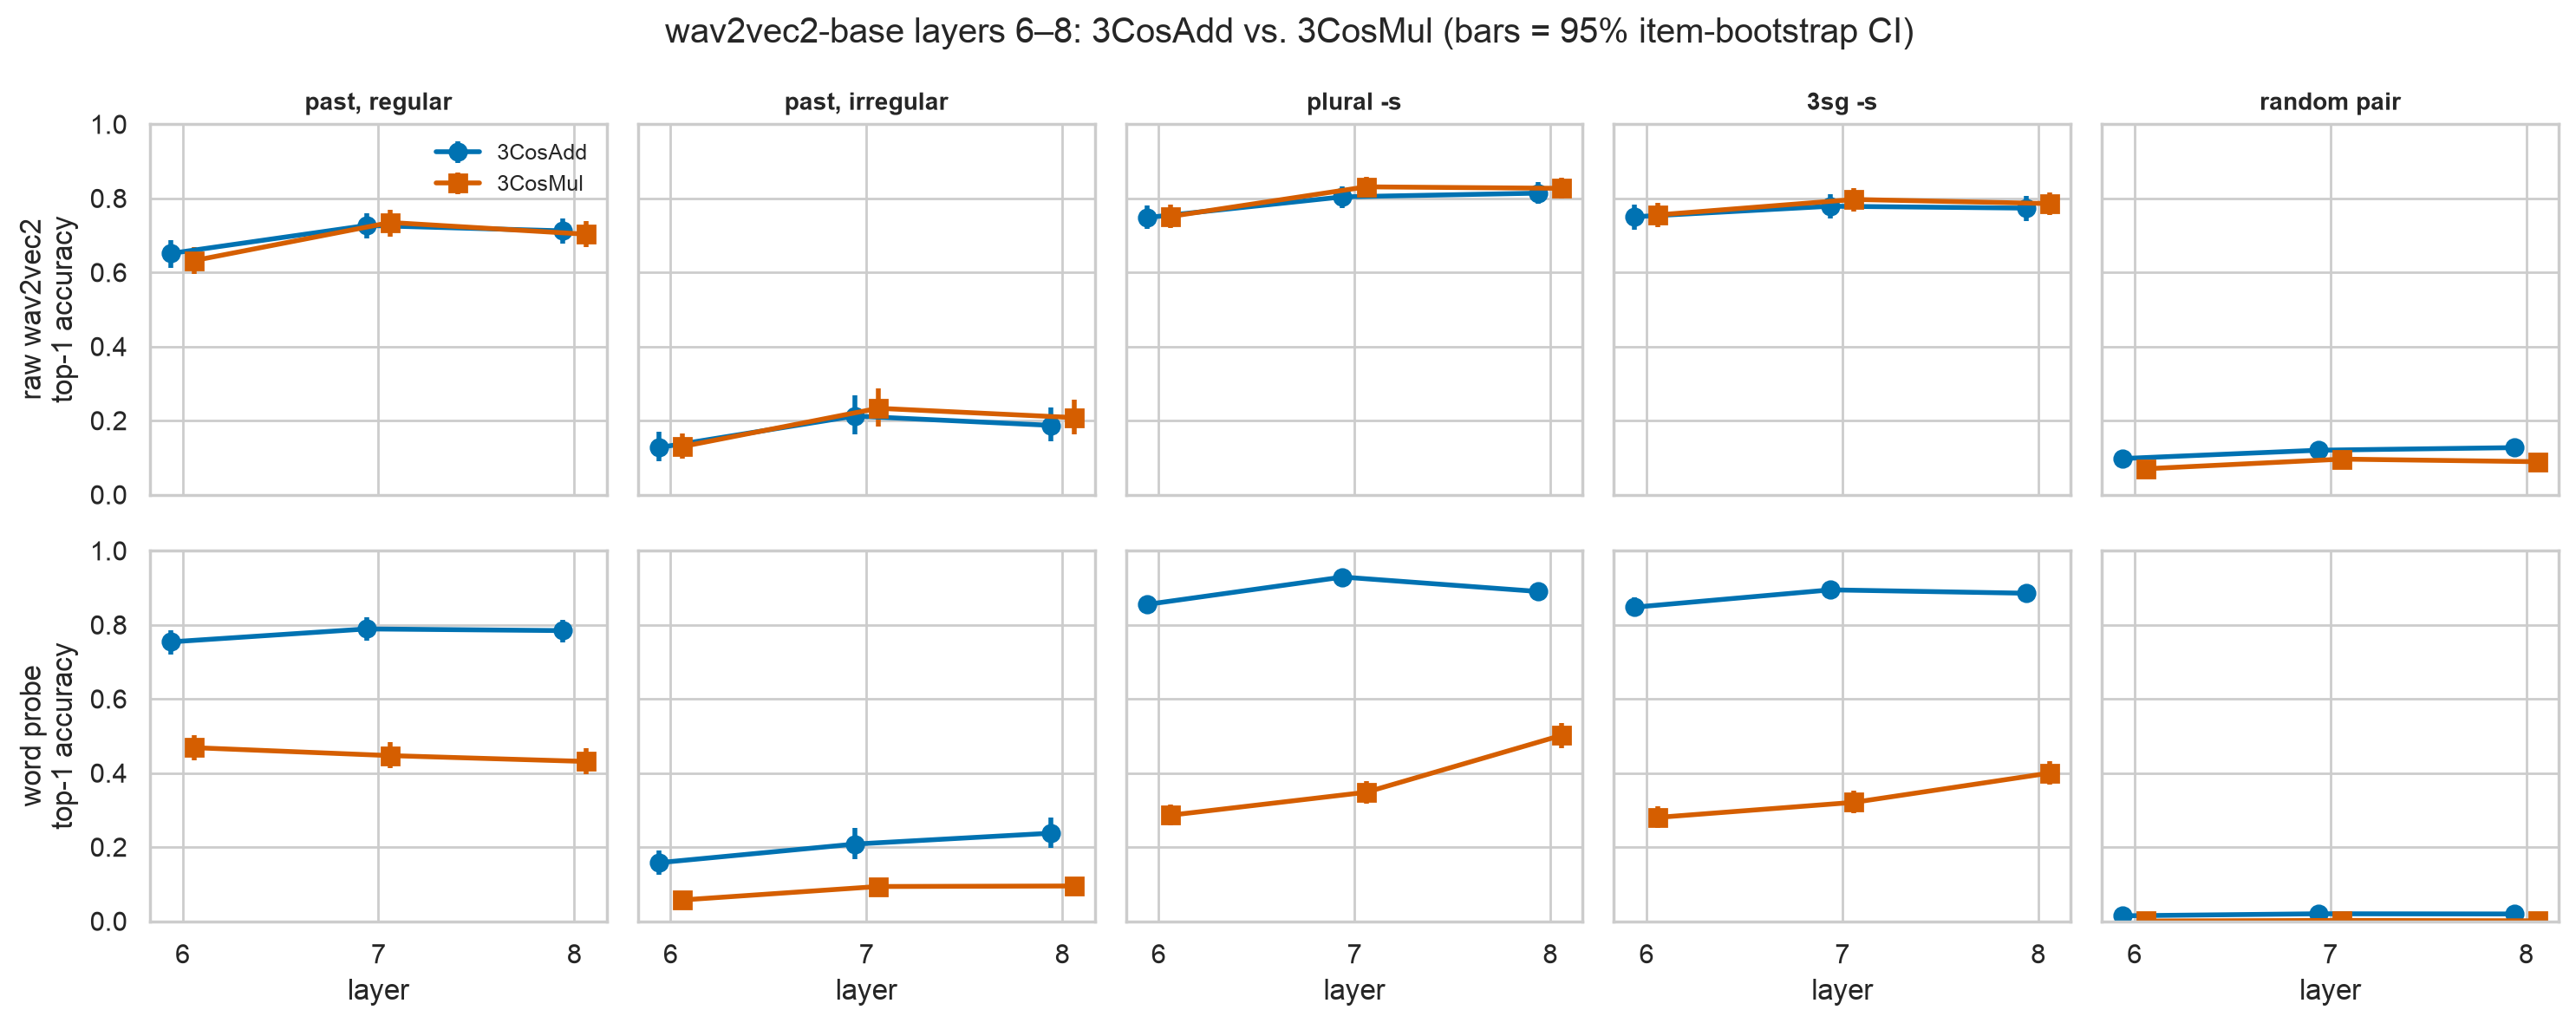

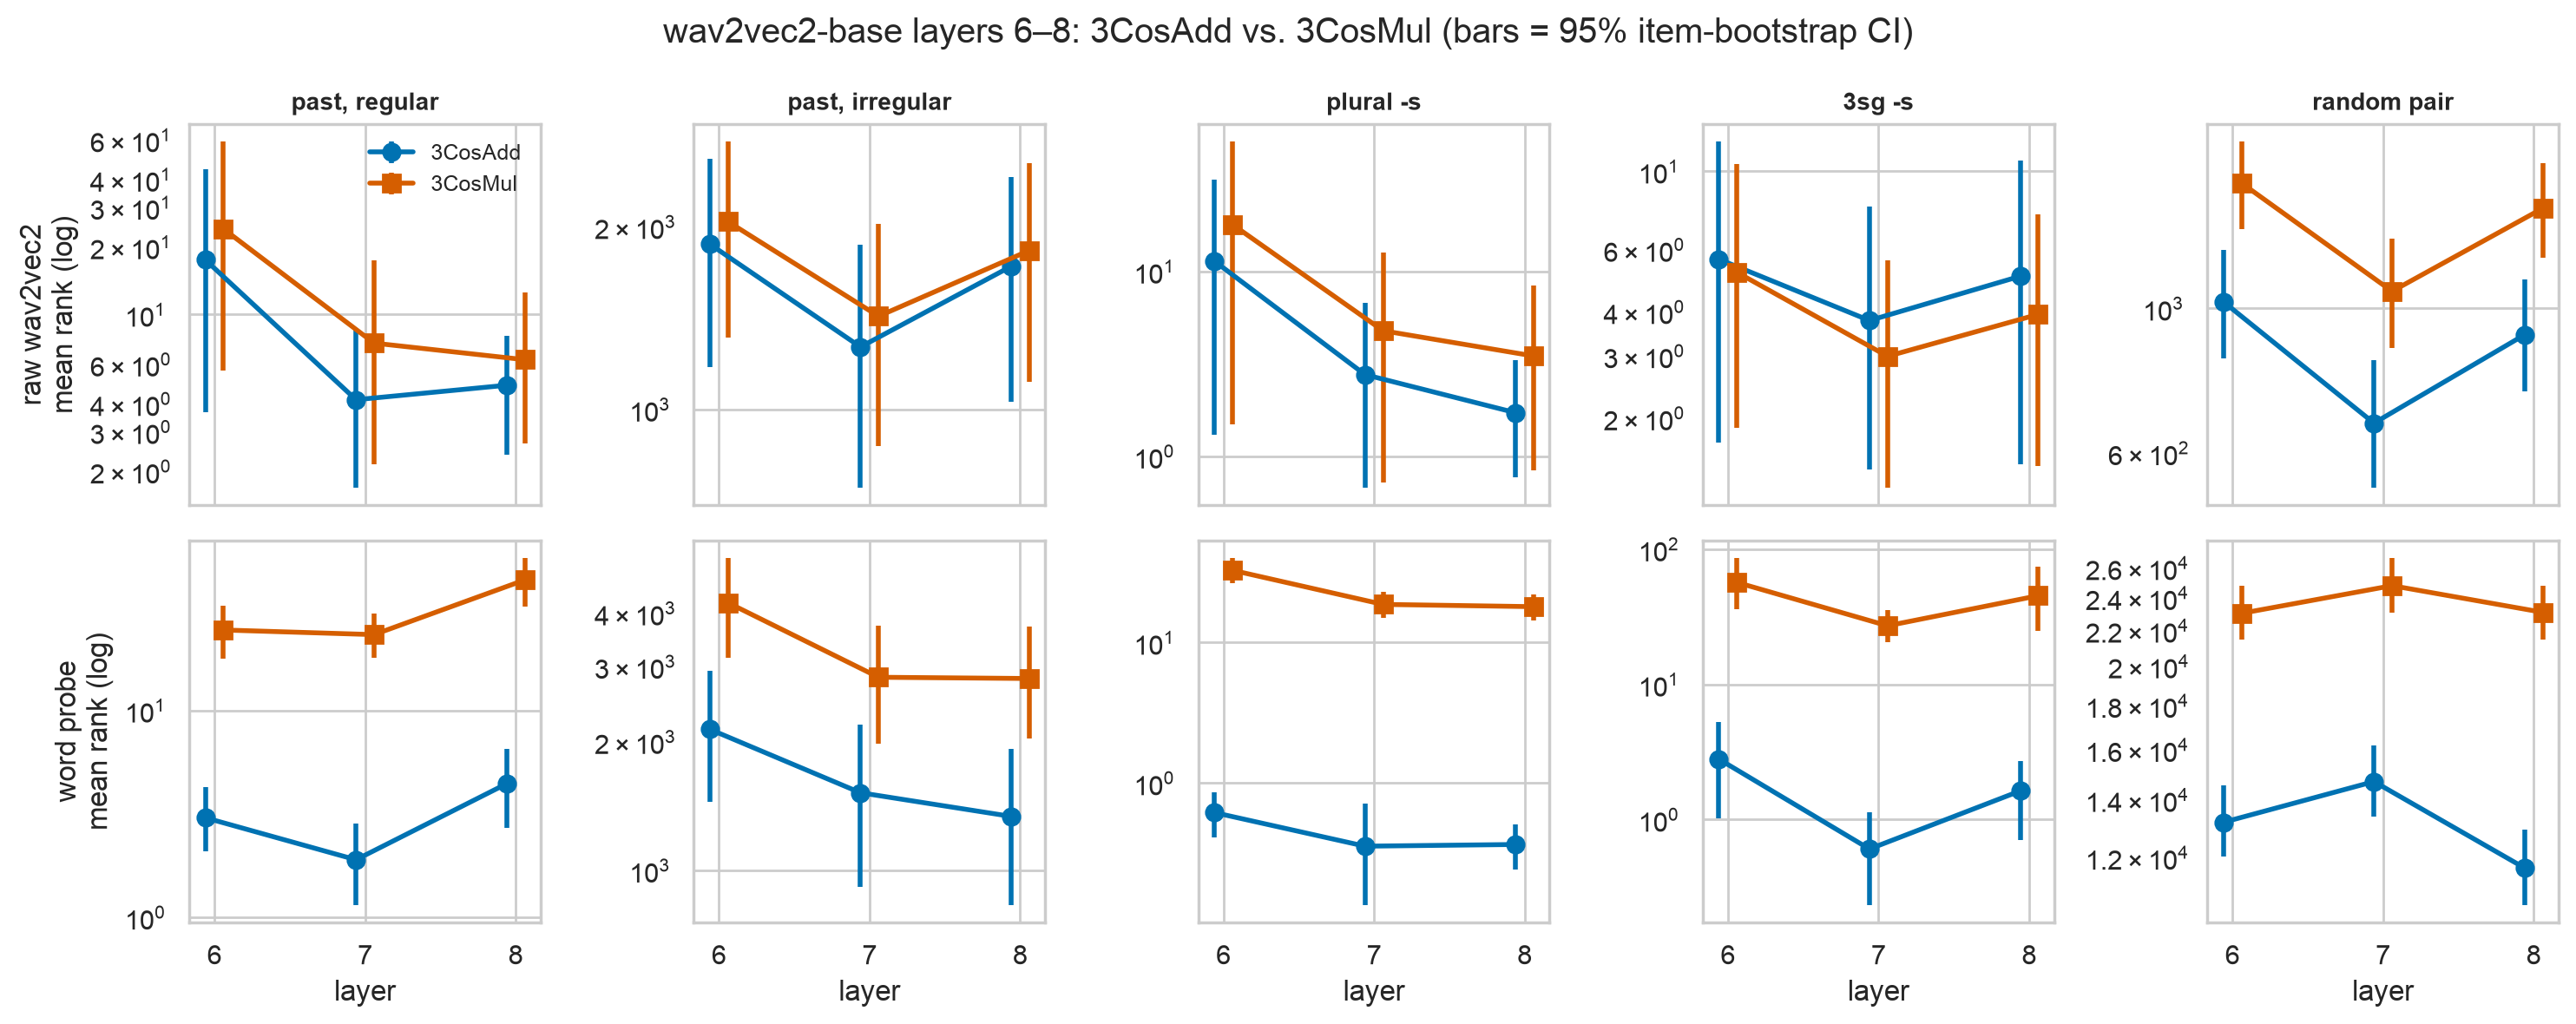

In [5]:
# Figure: each condition across layers 6-8, one panel per (measure, representation, condition)
def fig_conditions(est, lo, hi, ylabel, log, name):
    fig, axs = plt.subplots(len(MODELS), len(SHOW), figsize=(3.0 * len(SHOW), 3.0 * len(MODELS)), sharex=True,
                            sharey=not log, squeeze=False)
    for r, model in enumerate(MODELS):
        for k, cnd in enumerate(SHOW):
            ax = axs[r, k]
            for j, label in enumerate(METHODS):
                d = cond[(cond.model == model) & (cond.condition == cnd) & (cond.method == label)].sort_values("layer")
                x = d.layer + (j - 0.5) * 0.12
                ax.errorbar(x, d[est], yerr=[d[est] - d[lo], d[hi] - d[est]], fmt=MARKERS[label] + "-", ms=7, lw=2,
                            capsize=0, color=COLORS[label], label=label)
            if log: ax.set_yscale("log")
            else: ax.set_ylim(0, 1)
            ax.set_xticks(LAYERS)
            if r == 0: ax.set_title(NAMES[cnd], fontsize=10)
            if k == 0: ax.set_ylabel(f"{MODEL_NAMES[model]}\n{ylabel}")
            if r == len(MODELS) - 1: ax.set_xlabel("layer")
    axs[0, 0].legend(frameon=False, fontsize=9)
    fig.suptitle(f"wav2vec2-base layers {LAYERS[0]}–{LAYERS[-1]}: 3CosAdd vs. 3CosMul (bars = 95% item-bootstrap CI)")
    fig.tight_layout()
    savefig(fig, name)

fig_conditions("top1", "top1_lo", "top1_hi", "top-1 accuracy", False, "fig_conditions_top1")
fig_conditions("mean_rank", "mean_lo", "mean_hi", "mean rank (log)", True, "fig_conditions_meanrank")

## 5. Ranking: how close is the correct word?

Top-1 only says whether the correct word came *first*. Here, for each experiment, the share of trials with the correct word in the top 1, 5, 10 and 100, plus the median and mean rank. Rank 0 = the correct word is the nearest. A rule can lose top-1 accuracy but still put the correct word near the top (high top-5 / top-10, low median rank).

Rows: the experiment and inflection (`VBD` = past tense, `NNS` = plural, `VBZ` = 3sg, `VBG` = -ing, `NOT-latin` = the paper's control set; `basic` mixes them all); for `regular`, whether the source pair is regular (`True`) or irregular (`False`). This uses all trials of each experiment (no exclusions), so the numbers differ slightly from section 4.

In [6]:
KS = [1, 5, 10, 100]
p = paired.assign(inflection=paired.group0.fillna("–"),
                  regular=paired.group1.map(lambda g: "" if g is None or g != g else str(g)))
long = pd.concat([p.assign(method=label, rank=p[f"gt_label_rank_{s}"]) for label, s in [("3CosAdd", "add"), ("3CosMul", "mul")]],
                 ignore_index=True)
ranking = long.groupby(["model", "experiment", "inflection", "regular", "layer", "method"]).agg(
    trials=("rank", "size"), **{f"top-{k}": ("rank", lambda x, k=k: (x < k).mean()) for k in KS},
    median_rank=("rank", "median"), mean_rank=("rank", "mean"))
for model in MODELS:
    display(Markdown(f"**{MODEL_NAMES[model]}**"))
    display(ranking.loc[model].drop(columns="mean_rank").unstack("method").swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False).round(3))

**raw wav2vec2**

method                                 3CosAdd                                          3CosMul                                         
                                        trials  top-1  top-5 top-10 top-100 median_rank  trials  top-1  top-5 top-10 top-100 median_rank
experiment    inflection regular layer                                                                                                  
basic         NNS                6        1000  0.759  0.920  0.955   0.990         0.0    1000  0.750  0.921  0.946   0.990         0.0
                                 7        1000  0.809  0.949  0.971   0.995         0.0    1000  0.816  0.946  0.965   0.995         0.0
                                 8        1000  0.809  0.948  0.975   0.996         0.0    1000  0.807  0.947  0.969   0.993         0.0
              NOT-latin          6        1000  0.721  0.888  0.918   0.983         0.0    1000  0.704  0.886  0.916   0.973         0.0
                                 7        1000  0.775  0.935  0.958   0.993         0.0    1000  0.773  0.923  0.949   0.988         0.0
                                 8        1000  0.754  0.913  0.944   0.990         0.0    1000  0.749  0.905  0.941   0.984         0.0
              VBD                6        1000  0.553  0.730  0.788   0.896         0.0    1000  0.541  0.725  0.783   0.896         0.0
                                 7        1000  0.616  0.768  0.819   0.928         0.0    1000  0.609  0.766  0.815   0.926         0.0
                                 8        1000  0.602  0.765  0.806   0.915         0.0    1000  0.602  0.753  0.809   0.908         0.0
              VBG                6        1000  0.595  0.843  0.904   0.985         0.0    1000  0.670  0.881  0.918   0.985         0.0
                                 7        1000  0.651  0.886  0.939   0.991         0.0    1000  0.750  0.902  0.949   0.992         0.0
                                 8        1000  0.665  0.882  0.931   0.993         0.0    1000  0.718  0.903  0.943   0.991         0.0
              VBZ                6        1000  0.702  0.901  0.938   0.987         0.0    1000  0.700  0.889  0.940   0.982         0.0
                                 7        1000  0.745  0.915  0.952   0.993         0.0    1000  0.767  0.919  0.955   0.992         0.0
                                 8        1000  0.732  0.907  0.955   0.994         0.0    1000  0.733  0.910  0.946   0.990         0.0
              random             6        1000  0.000  0.000  0.000   0.005     43984.5    1000  0.000  0.000  0.000   0.006     42702.5
                                 7        1000  0.000  0.000  0.000   0.002     43954.5    1000  0.000  0.000  0.000   0.004     42650.0
                                 8        1000  0.000  0.000  0.000   0.004     44716.5    1000  0.000  0.000  0.000   0.004     44727.5
random_to_NNS –                  6        1000  0.108  0.236  0.309   0.591        47.5    1000  0.083  0.184  0.238   0.499       101.0
                                 7        1000  0.136  0.297  0.381   0.688        25.0    1000  0.111  0.236  0.306   0.607        41.5
                                 8        1000  0.139  0.281  0.357   0.662        29.0    1000  0.101  0.215  0.283   0.561        56.0
random_to_VBZ –                  6        1000  0.087  0.221  0.300   0.603        46.0    1000  0.057  0.159  0.216   0.478       115.0
                                 7        1000  0.104  0.262  0.350   0.685        28.0    1000  0.081  0.205  0.272   0.570        58.0
                                 8        1000  0.115  0.263  0.352   0.643        33.0    1000  0.077  0.189  0.266   0.515        85.5
regular       NNS        False   6         110  0.564  0.691  0.745   0.864         0.0     110  0.527  0.673  0.718   0.845         0.0
                                 7         110  0.582  0.764  0.782   0.918         0.0     110  0.573  0.755  0.800   0.927         0.0
                           

**word probe**

method                                 3CosAdd                                          3CosMul                                         
                                        trials  top-1  top-5 top-10 top-100 median_rank  trials  top-1  top-5 top-10 top-100 median_rank
experiment    inflection regular layer                                                                                                  
basic         NNS                6        1000  0.837  0.939  0.961   0.985         0.0    1000  0.300  0.534  0.626   0.903         3.0
                                 7        1000  0.903  0.972  0.979   0.990         0.0    1000  0.350  0.598  0.706   0.936         2.0
                                 8        1000  0.884  0.967  0.981   0.995         0.0    1000  0.476  0.695  0.765   0.947         1.0
              NOT-latin          6        1000  0.943  0.991  0.995   1.000         0.0    1000  0.812  0.934  0.963   1.000         0.0
                                 7        1000  0.958  0.998  1.000   1.000         0.0    1000  0.806  0.959  0.978   1.000         0.0
                                 8        1000  0.966  0.998  1.000   1.000         0.0    1000  0.837  0.956  0.975   0.999         0.0
              VBD                6        1000  0.610  0.763  0.802   0.904         0.0    1000  0.408  0.568  0.635   0.826         2.0
                                 7        1000  0.670  0.801  0.839   0.920         0.0    1000  0.353  0.549  0.625   0.837         3.0
                                 8        1000  0.643  0.770  0.802   0.888         0.0    1000  0.325  0.508  0.571   0.799         4.0
              VBG                6        1000  0.806  0.941  0.966   0.996         0.0    1000  0.268  0.505  0.616   0.924         4.0
                                 7        1000  0.848  0.951  0.964   0.991         0.0    1000  0.303  0.539  0.650   0.924         3.5
                                 8        1000  0.801  0.906  0.929   0.975         0.0    1000  0.291  0.499  0.588   0.881         5.0
              VBZ                6        1000  0.801  0.940  0.963   0.990         0.0    1000  0.262  0.496  0.614   0.913         5.0
                                 7        1000  0.880  0.967  0.984   0.996         0.0    1000  0.324  0.574  0.690   0.950         3.0
                                 8        1000  0.855  0.962  0.975   0.991         0.0    1000  0.399  0.653  0.742   0.948         1.0
              random             6        1000  0.000  0.000  0.000   0.000     86932.0    1000  0.000  0.000  0.000   0.002     88354.0
                                 7        1000  0.000  0.000  0.000   0.001     88228.0    1000  0.000  0.000  0.000   0.003     91969.0
                                 8        1000  0.000  0.000  0.000   0.001     89061.0    1000  0.000  0.000  0.001   0.001     89958.0
random_to_NNS –                  6        1000  0.015  0.030  0.049   0.158      2184.5    1000  0.000  0.001  0.005   0.038      8345.5
                                 7        1000  0.020  0.035  0.053   0.161      2502.0    1000  0.002  0.004  0.007   0.036      7887.5
                                 8        1000  0.017  0.039  0.055   0.163      1971.5    1000  0.001  0.006  0.006   0.032      8692.5
random_to_VBZ –                  6        1000  0.014  0.037  0.046   0.132      3005.0    1000  0.001  0.003  0.006   0.042      9360.0
                                 7        1000  0.020  0.038  0.051   0.135      3258.0    1000  0.002  0.003  0.006   0.034      9288.0
                                 8        1000  0.022  0.037  0.052   0.138      2484.5    1000  0.001  0.002  0.004   0.031      8882.5
regular       NNS        False   6         110  0.491  0.627  0.691   0.836         1.0     110  0.364  0.491  0.527   0.673         5.0
                                 7         110  0.518  0.655  0.718   0.955         0.0     110  0.382  0.500  0.527   0.773         4.5
                           

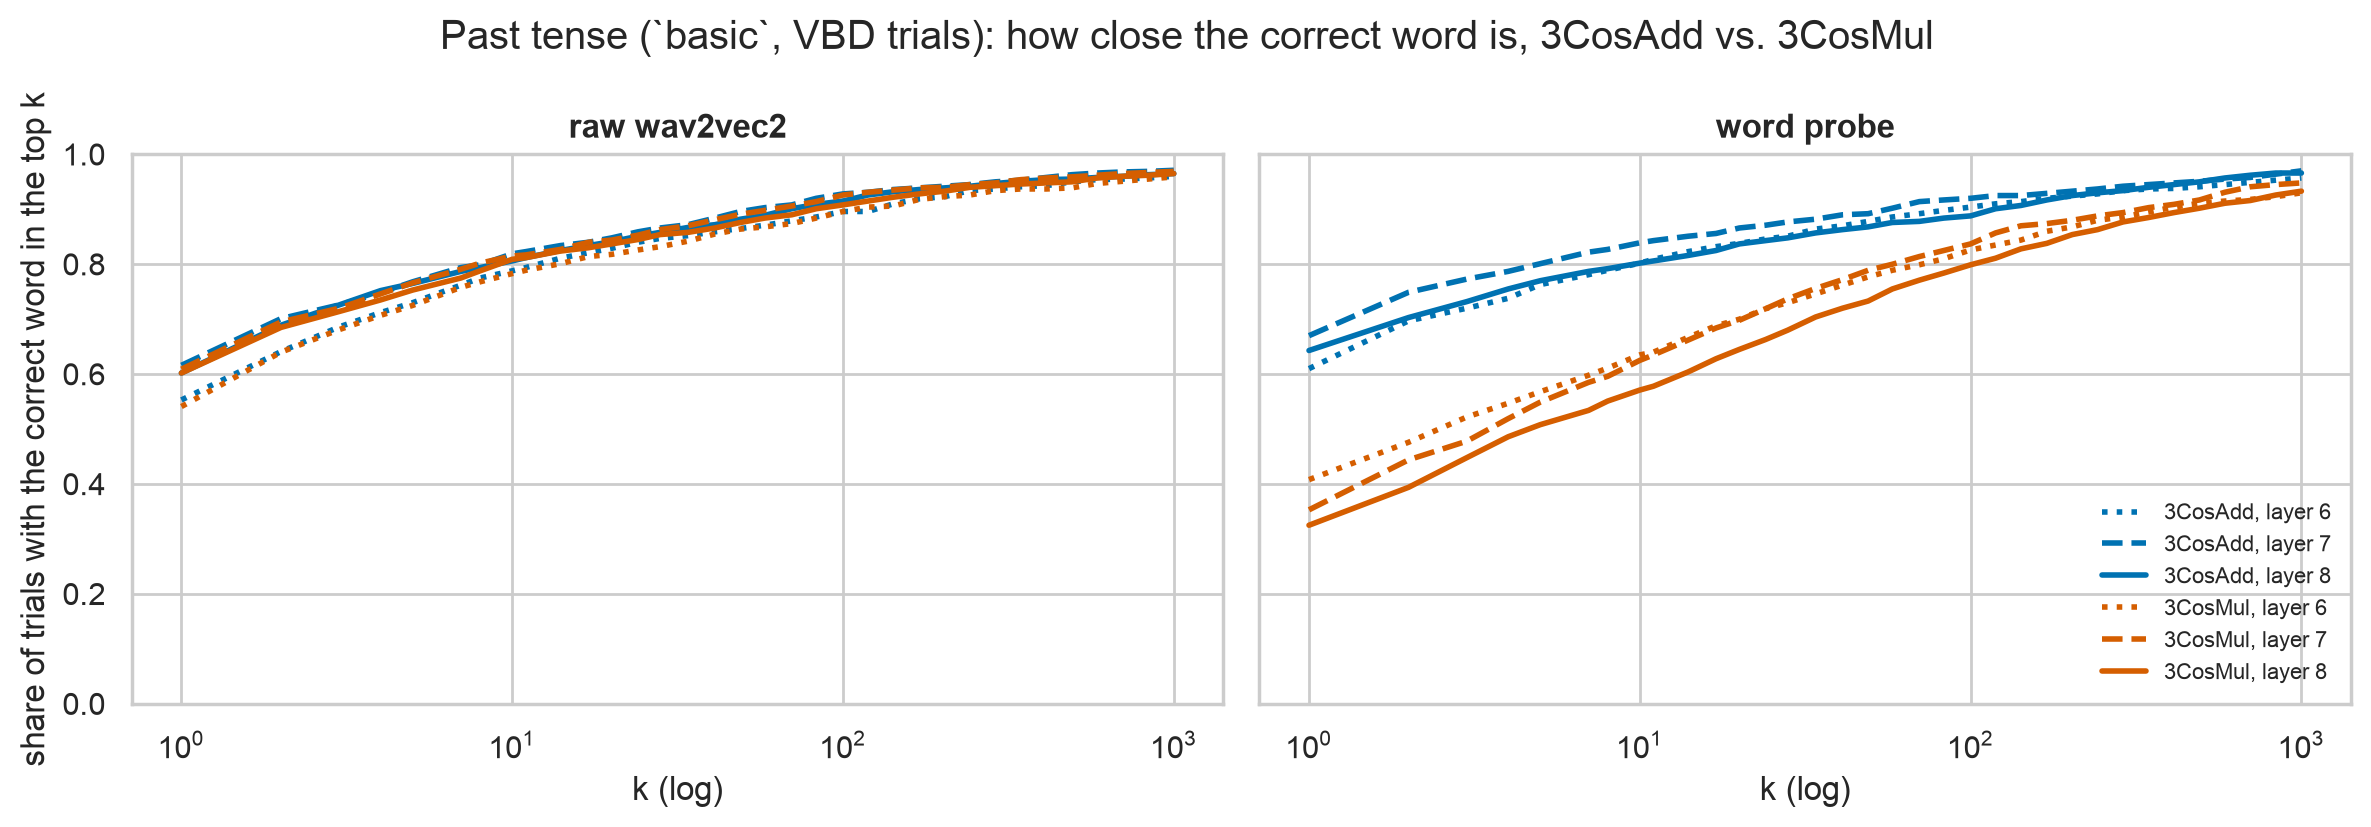

In [7]:
# Figure: share of trials with the correct word in the top k (k = 1..1000), past-tense trials of `basic`, per layer
kk = np.unique(np.logspace(0, 3, 40).astype(int))
fig, axs = plt.subplots(1, len(MODELS), figsize=(6 * len(MODELS), 4.2), sharey=True, squeeze=False)
styles = dict(zip(LAYERS, [":", "--", "-"]))
for ax, model in zip(axs[0], MODELS):
    for label in METHODS:
        for layer in LAYERS:
            r = long[(long.model == model) & (long.method == label) & (long.layer == layer) & (long.experiment == "basic") & (long.inflection == "VBD")]["rank"].to_numpy()
            ax.plot(kk, [(r < k).mean() for k in kk], styles[layer], color=COLORS[label], lw=2, label=f"{label}, layer {layer}")
    ax.set_xscale("log"); ax.set_ylim(0, 1)
    ax.set_xlabel("k (log)"); ax.set_title(MODEL_NAMES[model])
axs[0, 0].set_ylabel("share of trials with the correct word in the top k")
axs[0, -1].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Past tense (`basic`, VBD trials): how close the correct word is, 3CosAdd vs. 3CosMul")
fig.tight_layout()
savefig(fig, "fig_topk_basic")

## 6. Trial by trial: when does 3CosMul help, and when does it hurt?

Because both rules scored the same trials, each trial can be compared directly: did the correct word move **up** (better rank with 3CosMul), **down**, or stay the same? The trial-to-trial variation (some analogies are just hard) cancels out.

- **3CosMul better / worse / same**: share of trials.
- **top-1 gained / lost**: trials that became / stopped being exactly right.
- **median rank change**: 3CosMul rank − 3CosAdd rank; negative means 3CosMul is better.

In [8]:
q = p.assign(change=p.gt_label_rank_mul - p.gt_label_rank_add,
             top1_add=p.gt_label_rank_add == 0, top1_mul=p.gt_label_rank_mul == 0)
trial_cmp = q.groupby(["model", "experiment", "inflection", "regular", "layer"]).apply(lambda d: pd.Series({
    "trials": len(d),
    "3CosMul better": (d.change < 0).mean(), "3CosMul worse": (d.change > 0).mean(), "same": (d.change == 0).mean(),
    "top-1 gained": (d.top1_mul & ~d.top1_add).sum(), "top-1 lost": (d.top1_add & ~d.top1_mul).sum(),
    "median rank change": d.change.median()}), include_groups=False)
for model in MODELS:
    display(Markdown(f"**{MODEL_NAMES[model]}**"))
    display(trial_cmp.loc[model].round(3))

**raw wav2vec2**

trials  3CosMul better  3CosMul worse   same  top-1 gained  top-1 lost  median rank change
experiment    inflection regular layer                                                                                            
basic         NNS                6      1000.0           0.103          0.110  0.787          36.0        45.0                 0.0
                                 7      1000.0           0.070          0.076  0.854          34.0        27.0                 0.0
                                 8      1000.0           0.068          0.080  0.852          28.0        30.0                 0.0
              NOT-latin          6      1000.0           0.094          0.150  0.756          29.0        46.0                 0.0
                                 7      1000.0           0.068          0.107  0.825          30.0        32.0                 0.0
                                 8      1000.0           0.076          0.123  0.801          34.0        39.0                 0.0
              VBD                6      1000.0           0.185          0.216  0.599          30.0        42.0                 0.0
                                 7      1000.0           0.175          0.171  0.654          29.0        36.0                 0.0
                                 8      1000.0           0.183          0.187  0.630          36.0        36.0                 0.0
              VBG                6      1000.0           0.246          0.096  0.658         103.0        28.0                 0.0
                                 7      1000.0           0.229          0.066  0.705         114.0        15.0                 0.0
                                 8      1000.0           0.214          0.089  0.697          82.0        29.0                 0.0
              VBZ                6      1000.0           0.116          0.138  0.746          33.0        35.0                 0.0
                                 7      1000.0           0.125          0.081  0.794          46.0        24.0                 0.0
                                 8      1000.0           0.116          0.111  0.773          38.0        37.0                 0.0
              random             6      1000.0           0.577          0.422  0.001           0.0         0.0              -535.0
                                 7      1000.0           0.551          0.448  0.001           0.0         0.0              -345.0
                                 8      1000.0           0.553          0.446  0.001           0.0         0.0              -408.5
random_to_NNS –                  6      1000.0           0.198          0.707  0.095          14.0        39.0                15.0
                                 7      1000.0           0.194          0.672  0.134          16.0        41.0                 8.0
                                 8      1000.0           0.185          0.690  0.125          11.0        49.0                12.0
random_to_VBZ –                  6      1000.0           0.157          0.761  0.082          10.0        40.0                33.0
                                 7      1000.0           0.169          0.718  0.113          18.0        41.0                14.0
                                 8      1000.0           0.149          0.739  0.112           9.0        47.0                22.0
regular       NNS        False   6       110.0           0.173          0.291  0.536           3.0         7.0                 0.0
                                 7       110.0           0.191          0.191  0.618           4.0         5.0                 0.0
                                 8       110.0           0.209          0.227  0.564           1.0         4.0                 0.0
                         True    6      1000.0           0.113          0.108  0.779          46.0        43.0                 0.0
                                 7      1000.0           0.098          0.062  0.840          53.0        26.0

**word probe**

trials  3CosMul better  3CosMul worse   same  top-1 gained  top-1 lost  median rank change
experiment    inflection regular layer                                                                                            
basic         NNS                6      1000.0           0.034          0.672  0.294          16.0       553.0                 3.0
                                 7      1000.0           0.015          0.639  0.346          12.0       565.0                 2.0
                                 8      1000.0           0.016          0.506  0.478          10.0       418.0                 1.0
              NOT-latin          6      1000.0           0.014          0.169  0.817           8.0       139.0                 0.0
                                 7      1000.0           0.006          0.173  0.821           4.0       156.0                 0.0
                                 8      1000.0           0.008          0.156  0.836           8.0       137.0                 0.0
              VBD                6      1000.0           0.103          0.498  0.399          31.0       233.0                 0.0
                                 7      1000.0           0.075          0.582  0.343          25.0       342.0                 1.0
                                 8      1000.0           0.076          0.599  0.325          15.0       333.0                 2.0
              VBG                6      1000.0           0.028          0.710  0.262          11.0       549.0                 4.0
                                 7      1000.0           0.017          0.683  0.300          11.0       556.0                 3.0
                                 8      1000.0           0.028          0.678  0.294           7.0       517.0                 4.0
              VBZ                6      1000.0           0.046          0.707  0.247          26.0       565.0                 4.0
                                 7      1000.0           0.023          0.652  0.325           9.0       565.0                 2.0
                                 8      1000.0           0.038          0.567  0.395          22.0       478.0                 1.0
              random             6      1000.0           0.516          0.484  0.000           0.0         0.0              -294.0
                                 7      1000.0           0.497          0.503  0.000           0.0         0.0                63.0
                                 8      1000.0           0.483          0.517  0.000           0.0         0.0               355.5
random_to_NNS –                  6      1000.0           0.055          0.944  0.001           0.0        15.0              4369.5
                                 7      1000.0           0.049          0.949  0.002           0.0        18.0              4269.0
                                 8      1000.0           0.028          0.971  0.001           0.0        16.0              5292.5
random_to_VBZ –                  6      1000.0           0.040          0.960  0.000           1.0        14.0              4978.0
                                 7      1000.0           0.045          0.953  0.002           0.0        18.0              4881.0
                                 8      1000.0           0.043          0.956  0.001           0.0        21.0              5259.5
regular       NNS        False   6       110.0           0.073          0.509  0.418           1.0        15.0                 1.0
                                 7       110.0           0.091          0.491  0.418           2.0        17.0                 0.0
                                 8       110.0           0.027          0.482  0.491           2.0        17.0                 0.0
                         True    6      1000.0           0.027          0.689  0.284          10.0       579.0                 3.0
                                 7      1000.0           0.011          0.641  0.348           7.0       588.0

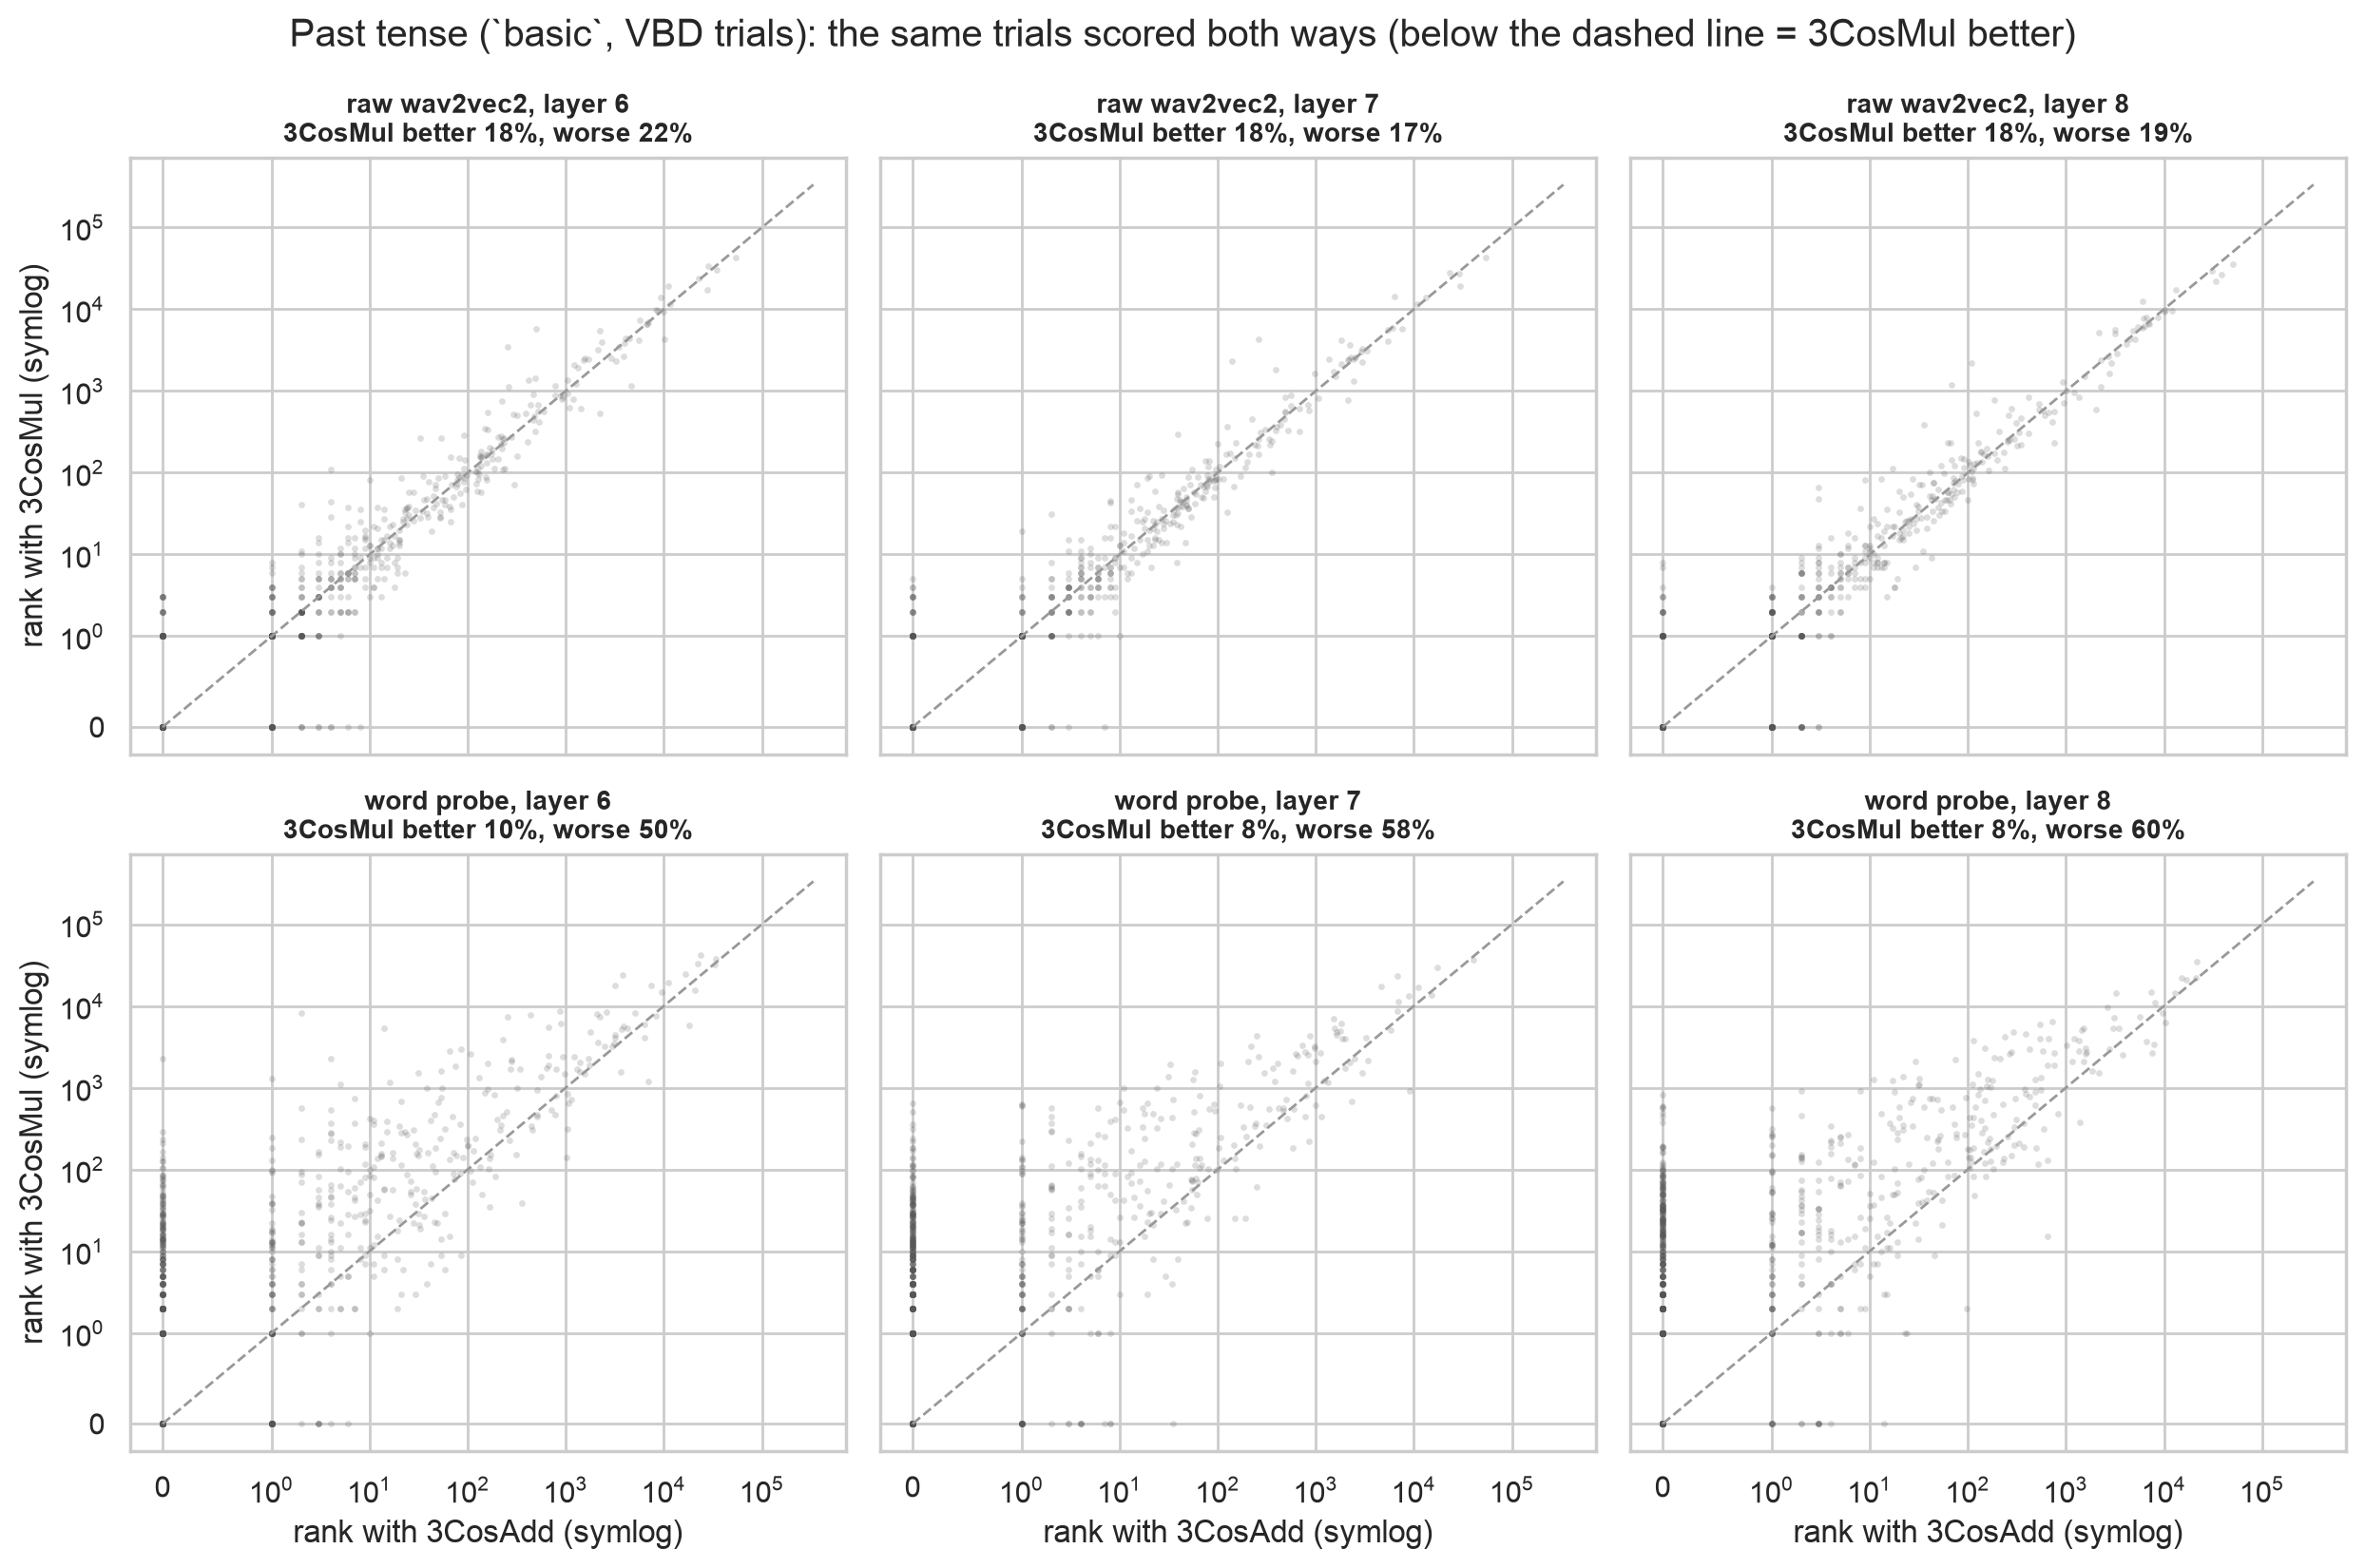

In [9]:
# Figure: 3CosAdd rank vs. 3CosMul rank for every past-tense (VBD) trial of `basic`, per layer and representation.
# Points below the diagonal: 3CosMul ranked the correct word higher. symlog so rank 0 is visible.
fig, axs = plt.subplots(len(MODELS), len(LAYERS), figsize=(4.2 * len(LAYERS), 4.2 * len(MODELS)), sharex=True, sharey=True, squeeze=False)
m = max(q.gt_label_rank_add.max(), q.gt_label_rank_mul.max())
for r, model in enumerate(MODELS):
    for k, layer in enumerate(LAYERS):
        ax, s = axs[r, k], q[(q.model == model) & (q.layer == layer) & (q.experiment == "basic") & (q.inflection == "VBD")]
        ax.scatter(s.gt_label_rank_add, s.gt_label_rank_mul, s=6, alpha=0.2, color="#555555", lw=0)
        ax.plot([0, m], [0, m], "--", color=C.CONTROL_COLOR, lw=1)
        ax.set_xscale("symlog", linthresh=1); ax.set_yscale("symlog", linthresh=1)
        ax.set_title(f"{MODEL_NAMES[model]}, layer {layer}\n3CosMul better {(s.change < 0).mean():.0%}, worse {(s.change > 0).mean():.0%}",
                     fontsize=10)
        if r == len(MODELS) - 1: ax.set_xlabel("rank with 3CosAdd (symlog)")
        if k == 0: ax.set_ylabel("rank with 3CosMul (symlog)")
fig.suptitle("Past tense (`basic`, VBD trials): the same trials scored both ways (below the dashed line = 3CosMul better)")
fig.tight_layout()
savefig(fig, "fig_trials_basic")

## 7. [t] / [d] / [ɪd] and irregular pasts: change in top-1

Feasibility Figure 6, as the **difference** 3CosMul − 3CosAdd in top-1 accuracy: rows are the source ending (*a : a\**), columns the target ending (*b : ?*); the last row and column are irregular pasts. Orange means 3CosMul is better in that cell, purple worse, white no change. Cells with few trials (see `n_trials` in the saved table) are noisy. The absolute values of each rule are in `allomorph_grid.csv`.

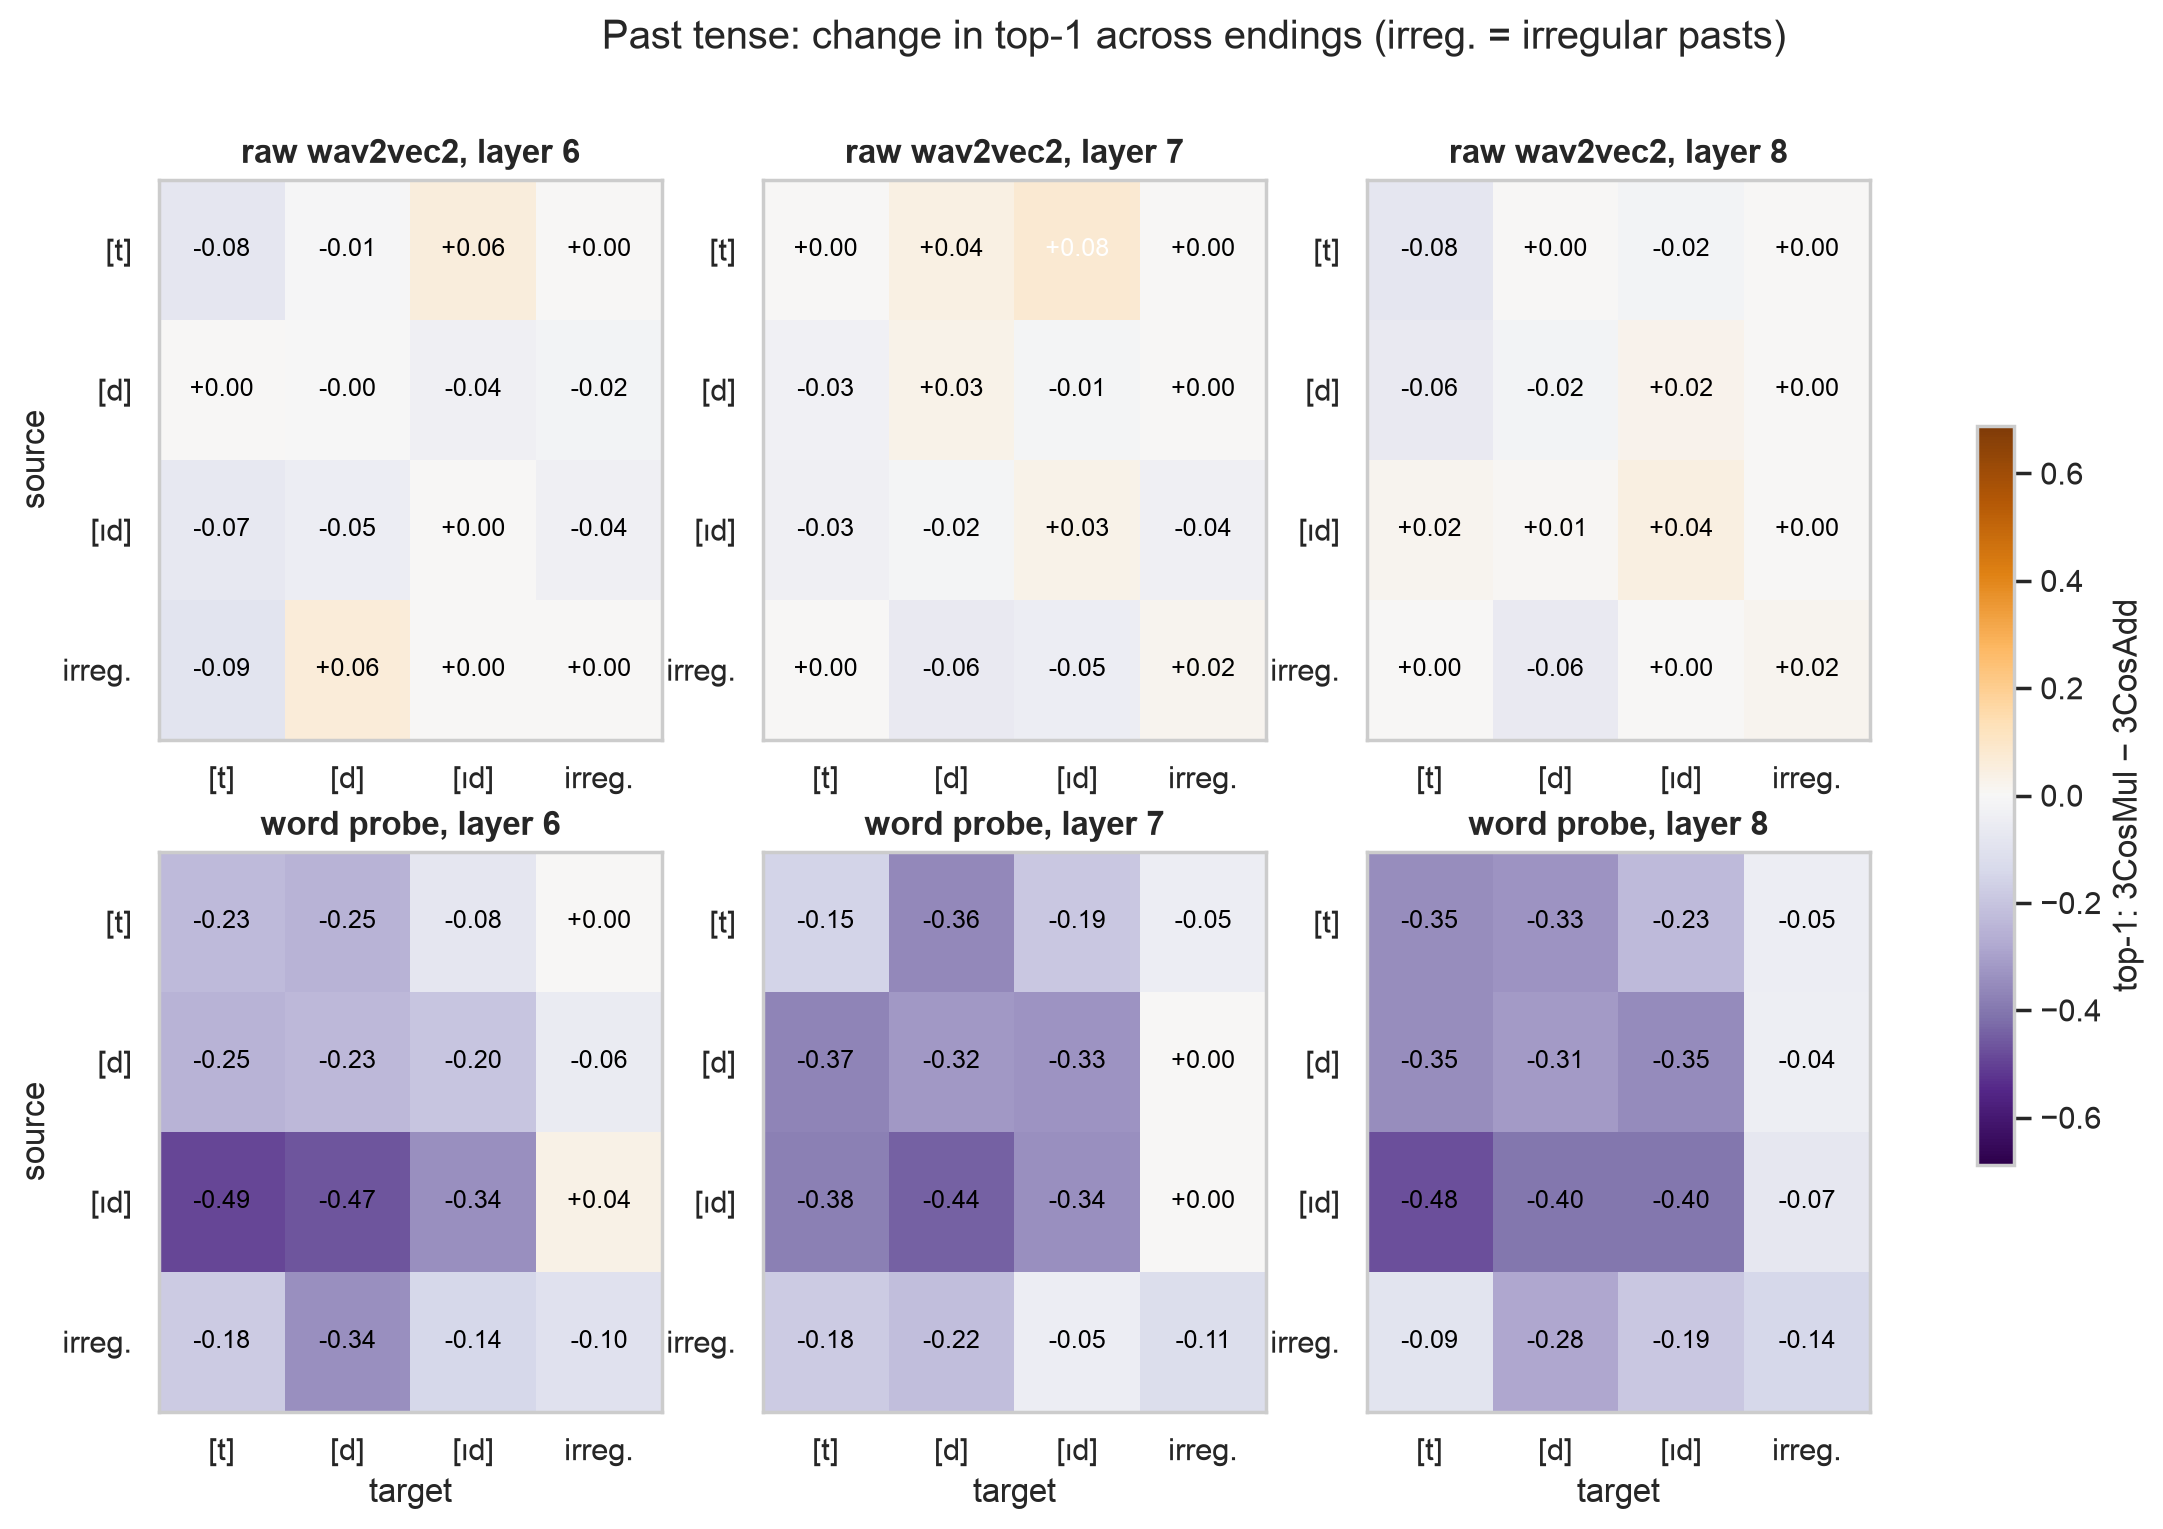

In [10]:
from matplotlib.colors import TwoSlopeNorm
cats = L.CATEGORIES
def cell_matrix(model, layer, label, est="top1"):
    s = grid[(grid.model == model) & (grid.layer == layer) & (grid.method == label)].set_index(["src", "tgt"])[est]
    return s.unstack().reindex(index=cats, columns=cats)

diffs = {(model, layer): cell_matrix(model, layer, "3CosMul") - cell_matrix(model, layer, "3CosAdd")
         for model in MODELS for layer in LAYERS}
lim = 1.4 * max(0.05, max(np.nanmax(np.abs(d.to_numpy())) for d in diffs.values()))   # one scale for all panels
fig, axs = plt.subplots(len(MODELS), len(LAYERS), figsize=(4.6 * len(LAYERS), 4.0 * len(MODELS)), squeeze=False)
for r, model in enumerate(MODELS):
    for k, layer in enumerate(LAYERS):
        d = diffs[model, layer]
        im = C.heatmap(axs[r, k], d, d.map(lambda x: f"{x:+.2f}" if np.isfinite(x) else "–"), TwoSlopeNorm(0, -lim, lim),
                       cmap="PuOr_r", title=f"{MODEL_NAMES[model]}, layer {layer}", ylabel="source" if k == 0 else "",
                       xlabel="target" if r == len(MODELS) - 1 else "")
fig.colorbar(im, ax=axs, shrink=0.6, label="top-1: 3CosMul − 3CosAdd")
fig.suptitle("Past tense: change in top-1 across endings (irreg. = irregular pasts)")
savefig(fig, "fig_allomorph_grid_diff")

### Mean rank and top-1 per ending, each rule

The same grids as `fig_layers_allomorph_grids_<model>[_meanrank]` from `scripts/layers/compare_layers.py` (same colour scales), for layers 6–8 only: one figure per representation, **rows = scoring rule, columns = layer**. Mean rank uses a log colour scale (as in the paper's Fig. 4; lower and lighter is better), top-1 a linear one (darker is better).

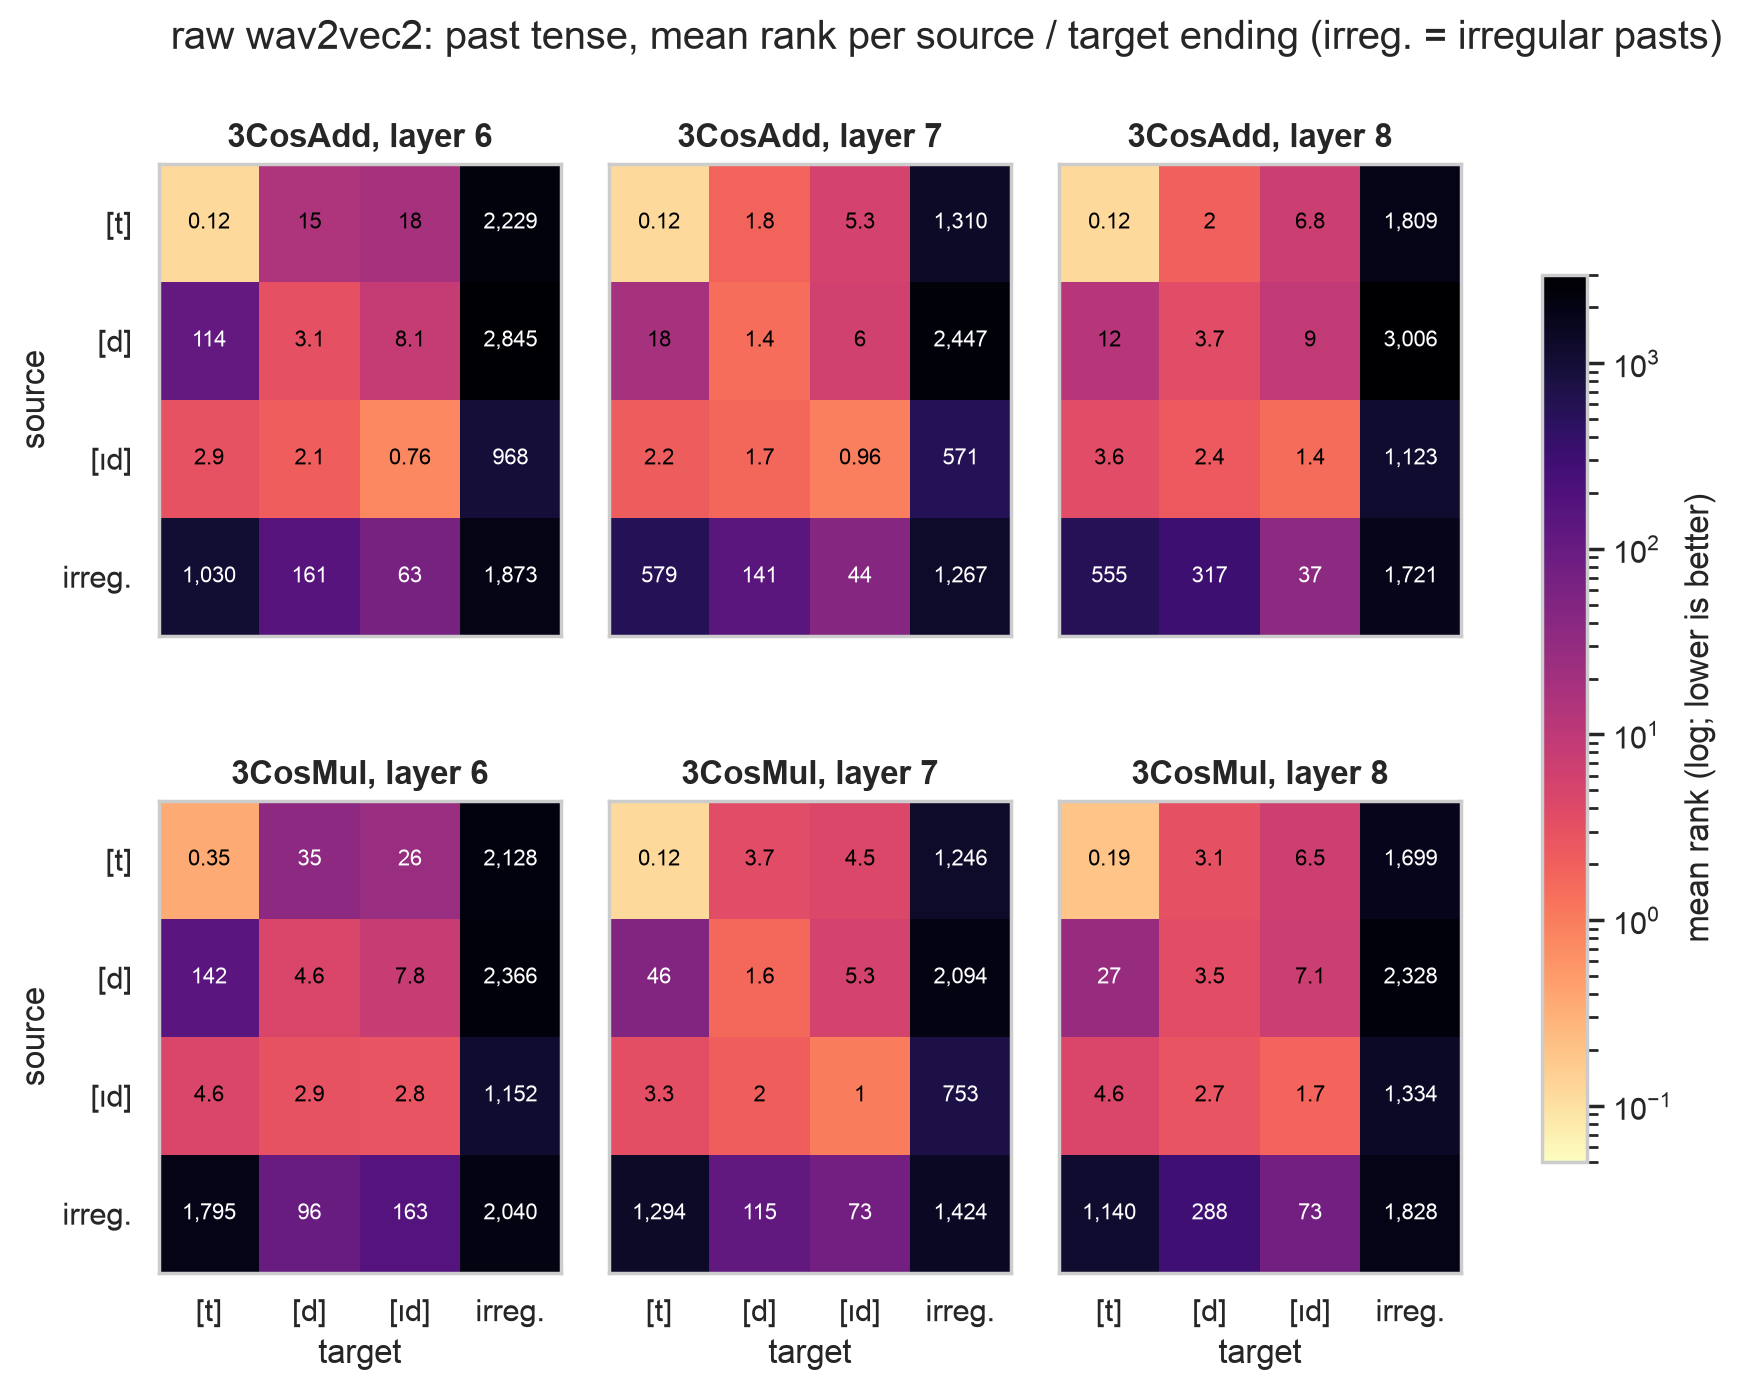

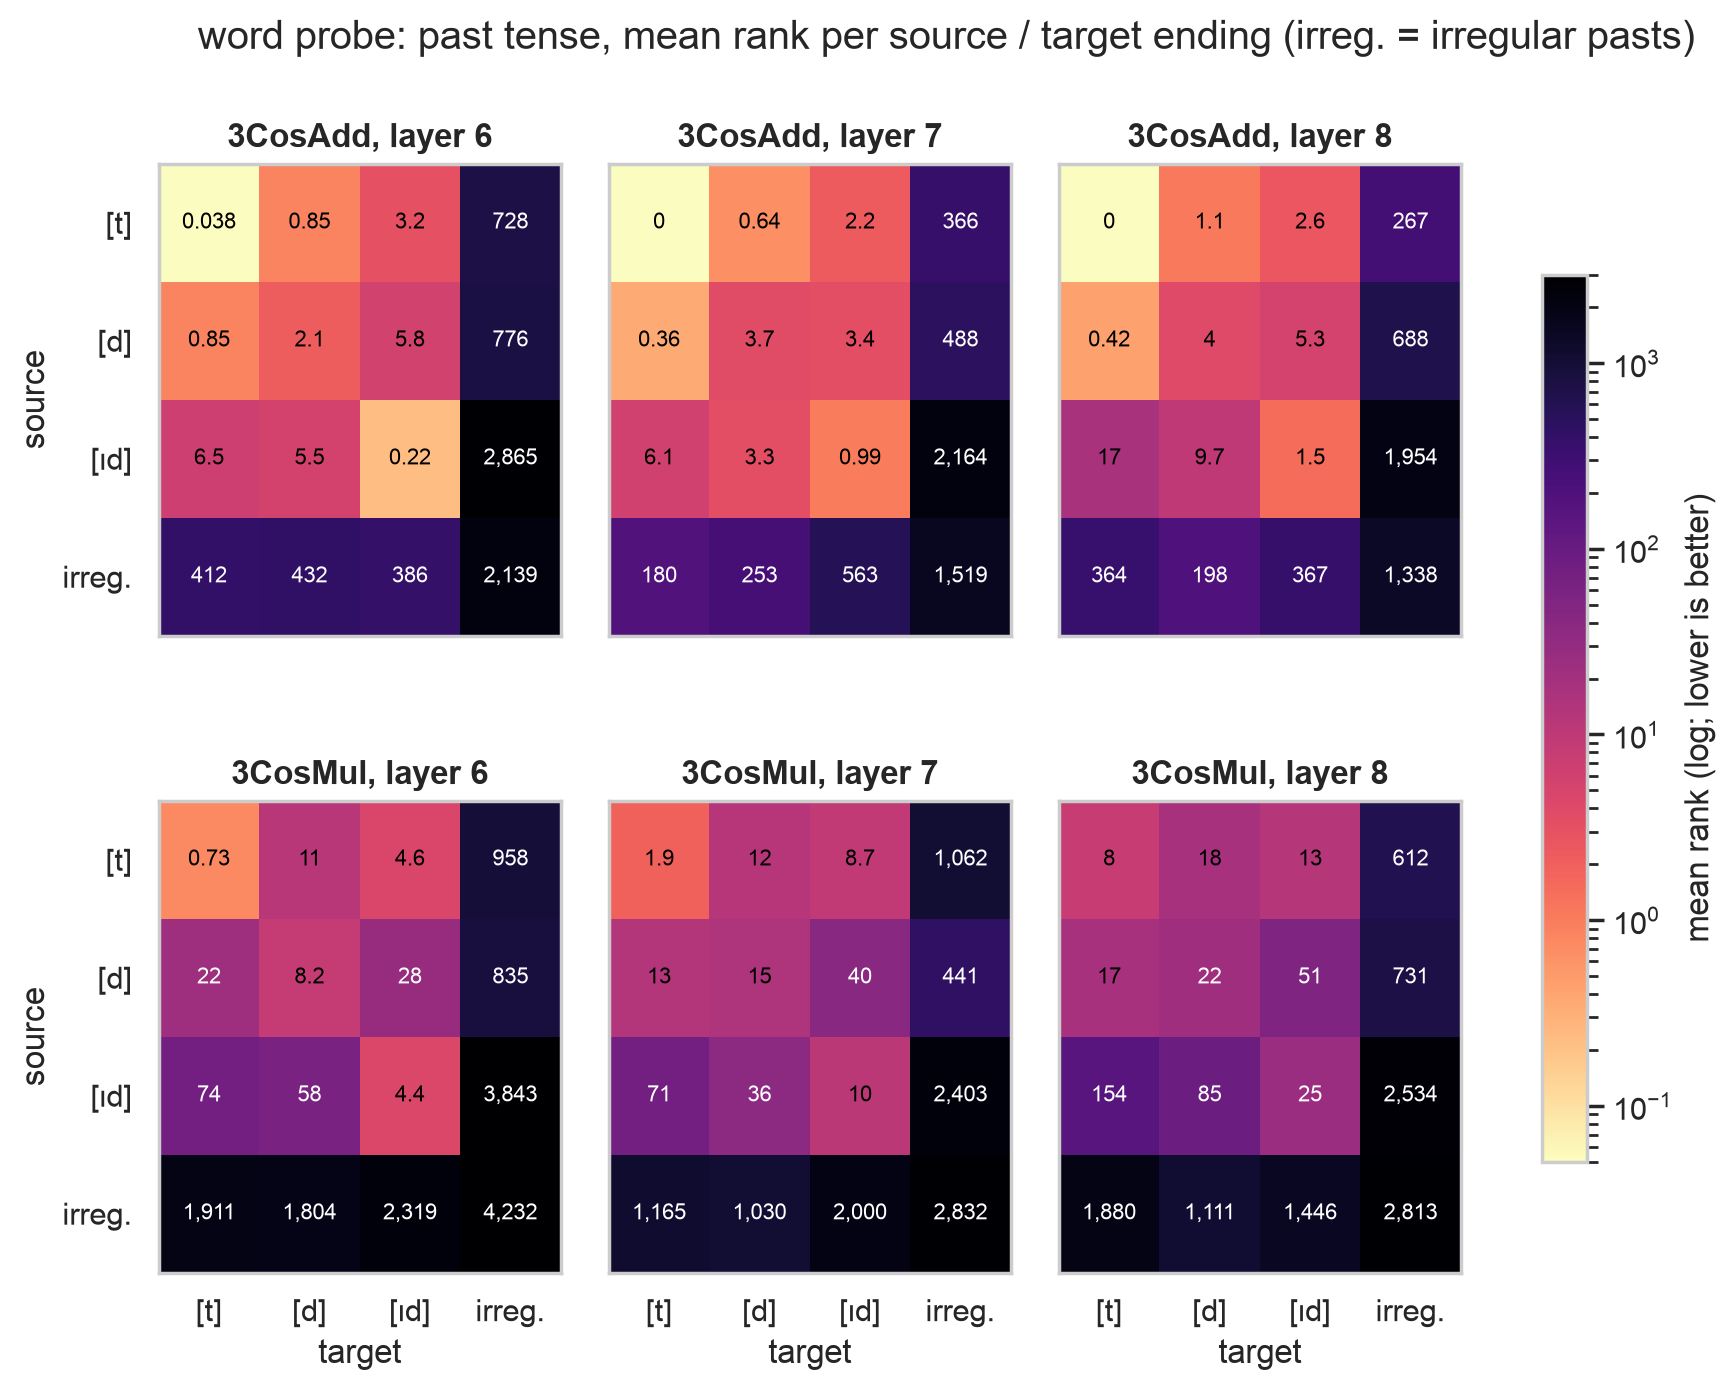

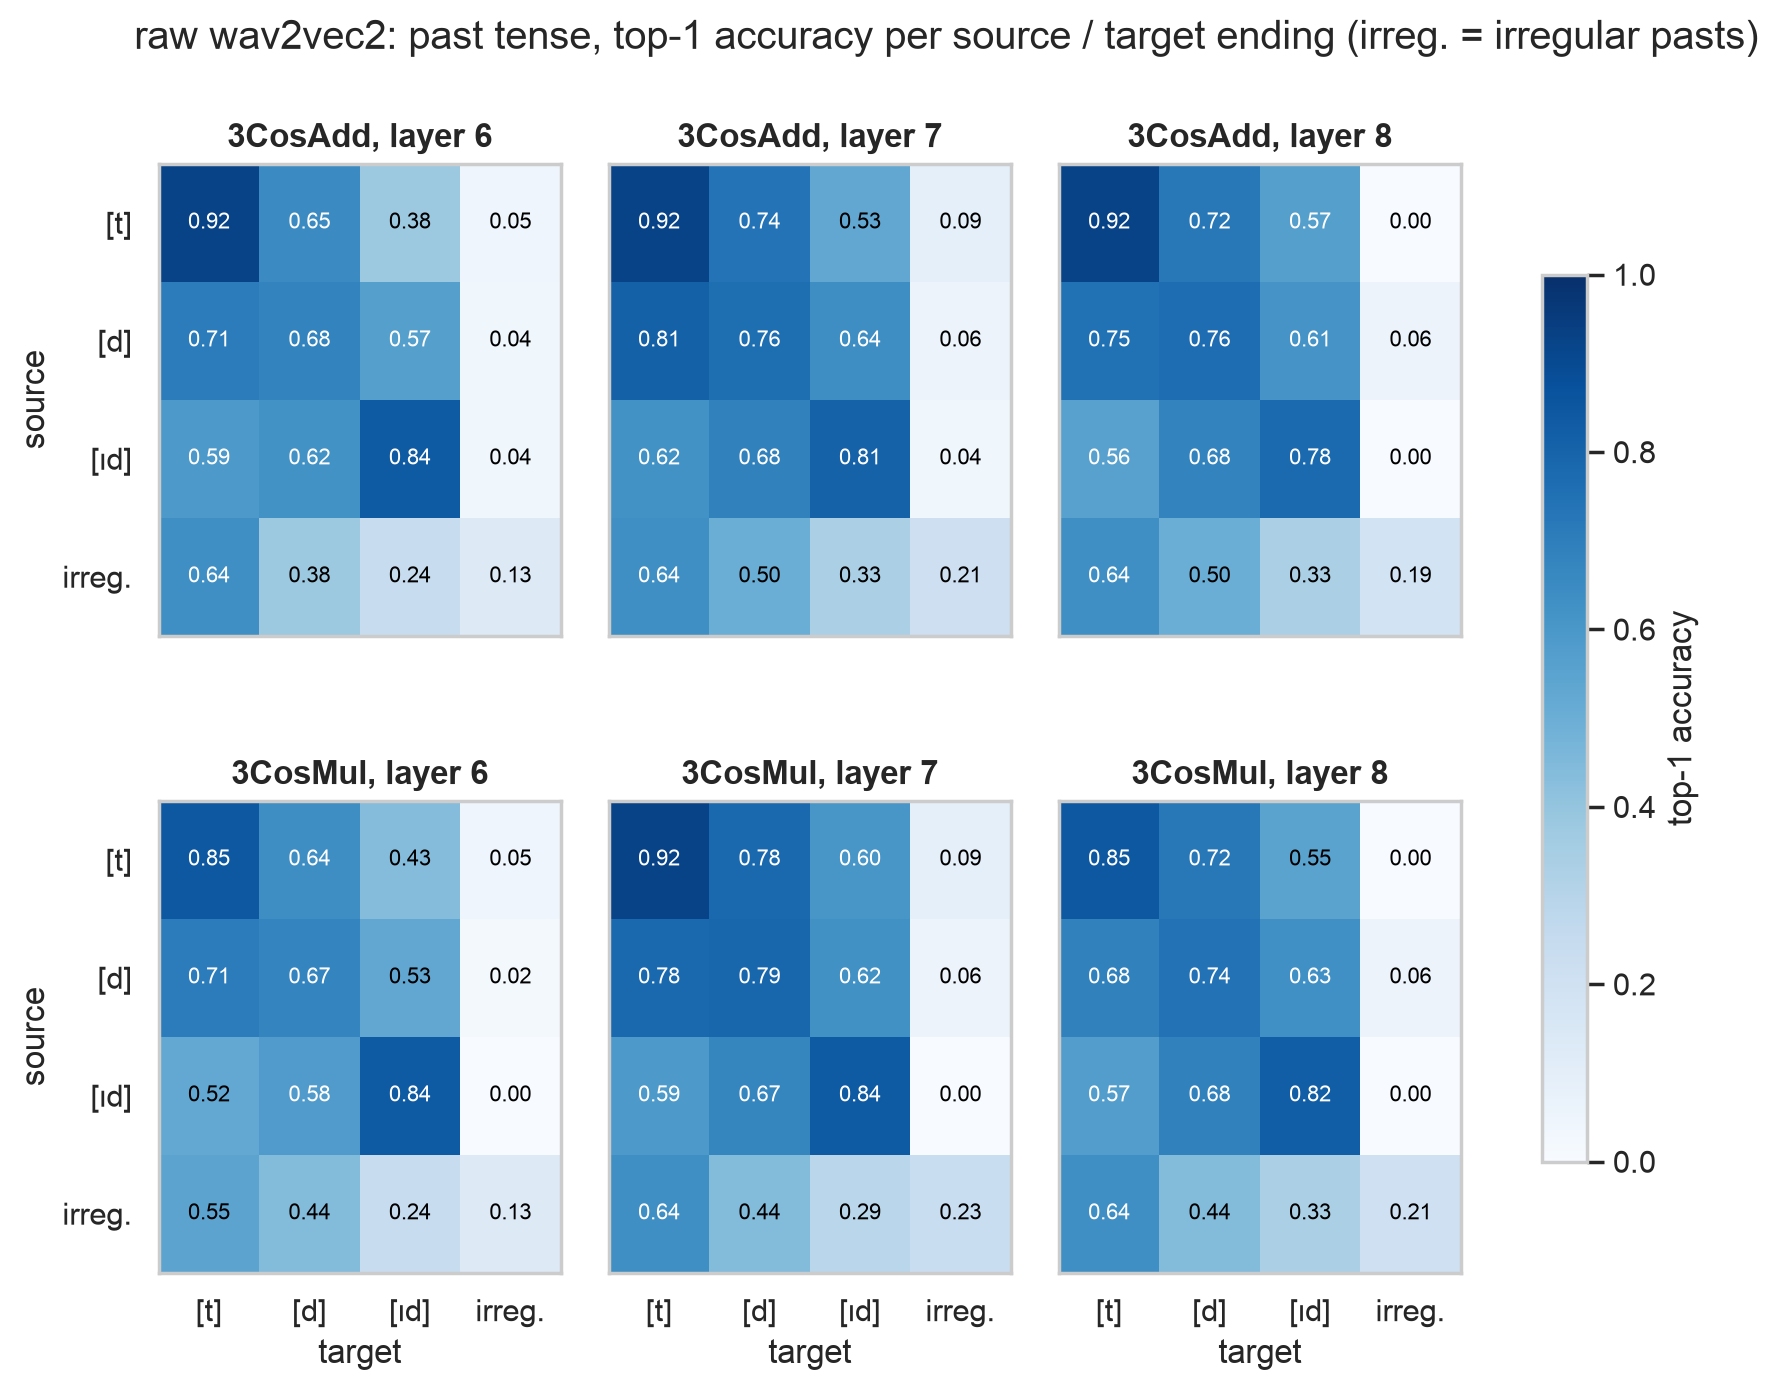

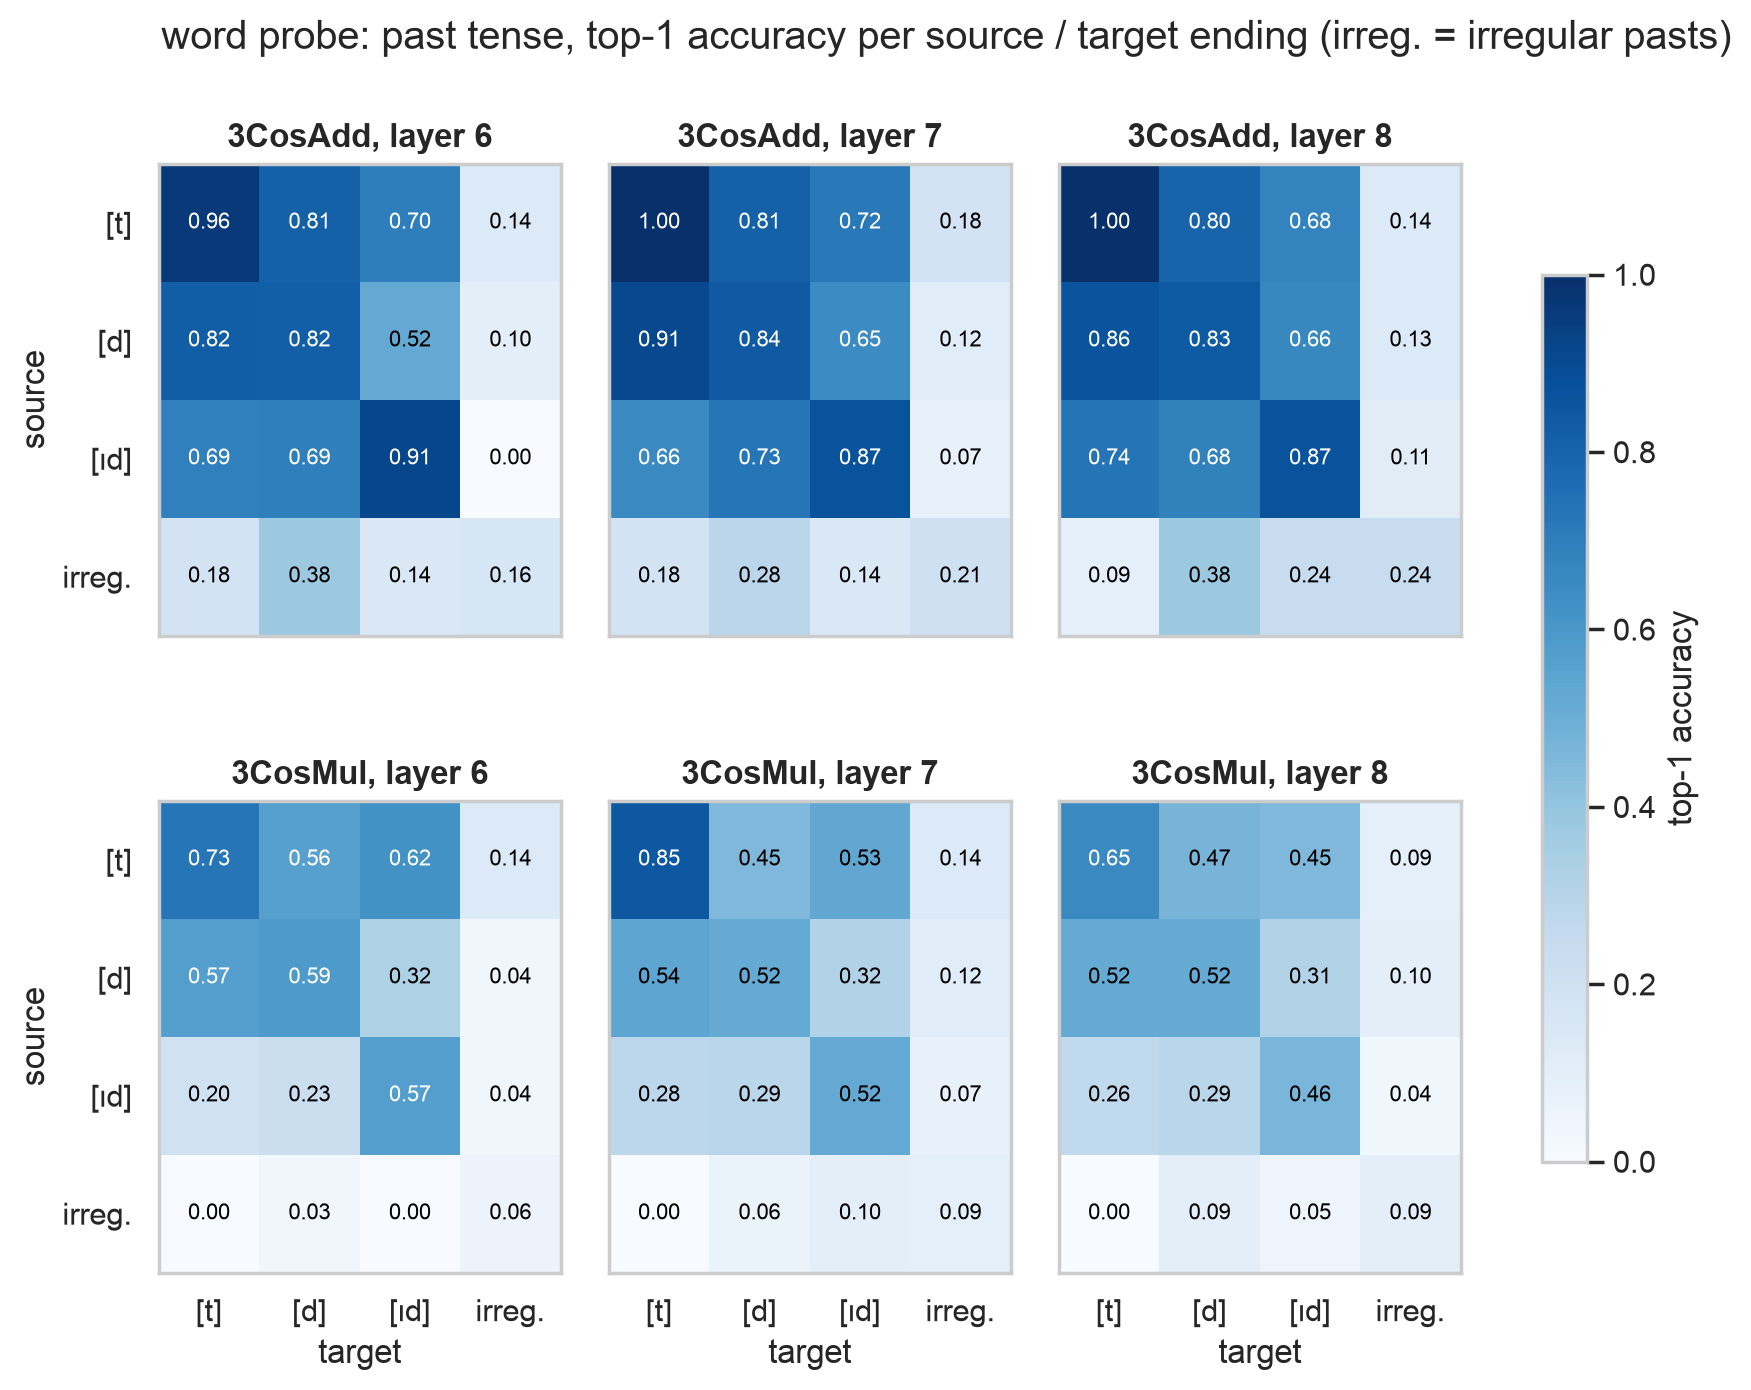

In [11]:
from matplotlib.colors import LogNorm, Normalize
GRID_METRICS = {
    "mean_rank": (LogNorm(vmin=0.05, vmax=3000, clip=True), "magma_r", "mean rank (log; lower is better)", C.fmt_rank),
    "top1": (Normalize(vmin=0, vmax=1), "Blues", "top-1 accuracy", lambda x: f"{x:.2f}" if np.isfinite(x) else "–"),
}
for metric, (norm, cmap, cbar, fmt) in GRID_METRICS.items():
    for model in MODELS:
        fig, axs = plt.subplots(len(METHODS), len(LAYERS), figsize=(3.1 * len(LAYERS) + 1.2, 3.2 * len(METHODS) + 0.8),
                                squeeze=False, gridspec_kw={"wspace": 0.12, "hspace": 0.35})
        for r, label in enumerate(METHODS):
            for k, layer in enumerate(LAYERS):
                ax, v = axs[r, k], cell_matrix(model, layer, label, metric)
                bottom, left = r == len(METHODS) - 1, k == 0
                colour = v.clip(lower=norm.vmin) if metric == "mean_rank" else v   # rank 0 would be "bad" on a log scale
                im = C.heatmap(ax, colour, v.map(fmt), norm, cmap=cmap, title=f"{label}, layer {layer}", fontsize=8,
                               xlabel="target" if bottom else "", ylabel="source" if left else "")
                if not bottom: ax.set_xticklabels([])
                if not left: ax.set_yticklabels([])
        fig.colorbar(im, ax=axs, label=cbar, shrink=0.8)
        fig.suptitle(f"{MODEL_NAMES[model]}: past tense, {cbar.split(' (')[0]} per source / target ending (irreg. = irregular pasts)")
        savefig(fig, f"fig_allomorph_grids_{model.lower()}_{'meanrank' if metric == 'mean_rank' else 'top1'}")

## 8. Save the tables

Writes to `outputs/feasibility/layers678_3cosadd_vs_3cosmul/tables/`:
- `conditions.csv`: section 4 (layer × representation × rule × condition).
- `ranking.csv`: section 5 (top-k shares, median and mean rank).
- `trial_comparison.csv`: section 6.
- `allomorph_grid.csv`: the ending grid of each rule (section 7).
- `per_verb.csv`: per target verb mean rank (regular past), each rule.

In [12]:
cond.to_csv(TABLES / "conditions.csv", index=False)
ranking.reset_index().to_csv(TABLES / "ranking.csv", index=False)
trial_cmp.reset_index().to_csv(TABLES / "trial_comparison.csv", index=False)
grid.to_csv(TABLES / "allomorph_grid.csv", index=False)
per_verb.to_csv(TABLES / "per_verb.csv", index=False)
for f in sorted(OUT.rglob("*.*")):
    print(f"{f.relative_to(REPO)}  ({f.stat().st_size / 1024:.0f} KB)")

outputs/feasibility/layers678_3cosadd_vs_3cosmul/figures/fig_allomorph_grid_diff.pdf  (32 KB)
outputs/feasibility/layers678_3cosadd_vs_3cosmul/figures/fig_allomorph_grid_diff.png  (224 KB)
outputs/feasibility/layers678_3cosadd_vs_3cosmul/figures/fig_allomorph_grids_wav2vec_meanrank.pdf  (32 KB)
outputs/feasibility/layers678_3cosadd_vs_3cosmul/figures/fig_allomorph_grids_wav2vec_meanrank.png  (193 KB)
outputs/feasibility/layers678_3cosadd_vs_3cosmul/figures/fig_allomorph_grids_wav2vec_top1.pdf  (31 KB)
outputs/feasibility/layers678_3cosadd_vs_3cosmul/figures/fig_allomorph_grids_wav2vec_top1.png  (205 KB)
outputs/feasibility/layers678_3cosadd_vs_3cosmul/figures/fig_allomorph_grids_word_meanrank.pdf  (32 KB)
outputs/feasibility/layers678_3cosadd_vs_3cosmul/figures/fig_allomorph_grids_word_meanrank.png  (196 KB)
outputs/feasibility/layers678_3cosadd_vs_3cosmul/figures/fig_allomorph_grids_word_top1.pdf  (31 KB)
outputs/feasibility/layers678_3cosadd_vs_3cosmul/figures/fig_allomorph_grids_wor